In [1]:
import os
# Отключает все логи TensorFlow (0 - все, 1 - предупреждения, 2 - ошибки, 3 - критичные ошибки)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

In [21]:
# Импортируем библиотеки

import torch
import torch.nn as nn
import torch.optim as optim
from torch_sparse import SparseTensor
from torch.utils.data import Dataset, DataLoader, TensorDataset, random_split
from transformers import BertTokenizer, BertModel
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, MaxAbsScaler
import tensorflow as tf
from keras.models import Model
from keras.layers import Input, Dense, Dropout, BatchNormalization, Lambda
from keras.regularizers import l1
from genre_recommender import preprocess_popularity, recommend_top_movies_by_genres, show_recommendations, get_all_genres
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics.pairwise import euclidean_distances, cosine_distances
from scipy.sparse import csr_matrix
import implicit
from implicit.als import AlternatingLeastSquares
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.decomposition import NMF, TruncatedSVD
from scipy.sparse import coo_matrix
from tqdm import tqdm
import json
import os
import math
import glob
import dill
import matplotlib.pyplot as plt
import hdbscan
from sklearn.model_selection import train_test_split
from keras.optimizers import Adam
from keras.losses import MeanSquaredError
import psutil
import time
import tracemalloc
import multiprocessing as mp
from sklearn.cluster import DBSCAN
import traceback
import sys
import gc
from sklearn.cluster import SpectralClustering
from multiprocessing import Process, Queue
from sklearn.mixture import GaussianMixture
import joblib
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
from implicit.nearest_neighbours import bm25_weight
from datetime import datetime
import lightgbm as lgb
import rbo
from matplotlib_venn import venn2
from sklearn.metrics import precision_score
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict, Counter, OrderedDict
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error
from scipy.sparse import hstack
import umap

# 1. Введение
Цель проекта: Построение рекомендательной системы, способной обрабатывать как холодный старт, так и динамическое добавление новых фильмов и пользователей.

# Основные задачи:

1. Холодный старт. Юзер новый и хочет рекомендаций- Юзер выбирает жанр и мы выдаем топ -5 по populatiry (в соответствии с жанром). 
2. Юзер посмотрел несоклько фильмов - подбираем похожий фильм (жанр, и тэги с учетом их весов (relevance)).  Предусмотреть динамическое добавление фильмов
3. Юзер посмотрел несколько фильмов и поставил рейтинг менее 5 раз но больше 0. Или более 5 раз, но положительных (3 и ниже) менее 3. Предусмотреть динамическое добавление фильмов
4. Юзер Поставил рейтинг 5+раз  - подбираем рекомендации ( в соответвии с его рейтингами). Выдаем рекомендации по кластеризированному user-vector. Предусмотреть динамическое добавление пользователей
5. Предусмотреть продвижение/блокировку фильмов.




# 2. Описание методов

Часть 1.

1. Холодный старт. Расчитываем средневзвешенную популярность фильма и выдаем (основная задача 1)
2. Подготовка данных для контента (movies_vector)  
    - Собираем вектор
    - Нормализуем  сохраняя scaler
    - Понижаем размерность сохраняя encoder
    - Создаем модель (KMeans))
4. Создаем функцию рекомендации по кластеризированным данным с выводом расчетных расстояний (для презентационной части)  (основная задача 2)
5. Оффлайн тестирование
6. Создаем функцию продвижение/блокировку фильмов (создаем спец датасет с этими данными и фильтруем на этапе выдачи рекомендаций. Блокированные фильмы просто не выдаем. Продвигаемые - выдаем отдельно с пометкой "Специальное предложение!!".)  (основная задача 5)

Часть 2.

7. Создаем матрицу взаимодействий.  
8. с помощью Implicit ALS получаем из матрицы взаимодействий item_factors.
   - обрезаем его по размеру movies_vector(т.к фильмов с тэгами сущетсвено меньше чем фильмов вообще)
9. Готовим чистый контент вектор
10. Объединяем item_factors с movies_vector 
    - Понижаем размерность сохраняя encoder
    - Создаем модель (KMeans))
11. Оффлайн тестирование

12. Создаем функцию динамического добавления фильма:   
    - добавляем фильм в датасет movies
    - добавляем фильм в датасет ratings с нулевым рейтингом
    - формируем вектор фильма для movies
    - формируем вектор фильма для item_factors
    - Объединяем item_factors с movies_vector  для конкретного фильма и
    - Применяем scaler.transform(), пропускаем через encoder.predict(), отправляем в KMeans.predict()

Часть 3.

13. Понижаем размерность матрицы взаимодействий encoder-ом (реалзиованно)
    -  Создаем модель (KMeans)  (реализованно)
    -  Создаем функцию рекомендации по кластеризированным данным с выводом расчетных расстояний (для презентационной части)  (основная задача 5)
14. Оффлайн тестирование
15. Создаем функцию динамического добавления пользователя:  
    - добавляем пользователя в датасет ratings 
    - пропускаем через encoder.predict(), отправляем в KMeans.

In [3]:
movies = pd.read_csv('content/films/movies.csv')
ratings = pd.read_csv('content/films/ratings.csv')
tags = pd.read_csv('content/films/tags.csv')
genome_tags = pd.read_csv('content/films/genome-tags.csv')
genome_scores = pd.read_csv('content/films/genome-scores.csv')
importance_df = pd.DataFrame(columns=['movieId', 'importance_score'])

# Проверим размеры
print("movies:", movies.shape)
print("ratings:", ratings.shape)
print("tags:", tags.shape)
print("genome_tags:", genome_tags.shape)
print("genome_scores:", genome_scores.shape)

movies: (86537, 3)
ratings: (33832162, 4)
tags: (2328315, 4)
genome_tags: (1128, 2)
genome_scores: (18472128, 3)


# Часть 1.

## 1. Холодный старт

In [24]:
popularity_df = preprocess_popularity(ratings)

# Непосредственно рекомендации
recommend_top_movies_by_genres("Action", "Adventure", movies_df=movies, popularity_df=popularity_df)

,title,genres,ave_rating,rating_count,weighted_rating
44066,Band of Brothers (2001),Action|Drama|War,4.423986,2835,4.419025
1930,Seven Samurai (Shichinin no samurai) (1954),Action|Adventure|Drama,4.250818,17120,4.250095
41020,Over the Garden Wall (2013),Adventure|Animation|Drama,4.256993,1430,4.248352
2867,Fight Club (1999),Action|Crime|Drama|Thriller,4.236019,86207,4.235877
82617,Spider-Man: Across the Spider-Verse (2023),Action|Adventure|Animation|Sci-Fi,4.252841,528,4.229790
5509,Spirited Away (Sen to Chihiro no kamikakushi) ...,Adventure|Animation|Fantasy,4.226035,35375,4.225692
55378,Spider-Man: Into the Spider-Verse (2018),Action|Adventure|Animation|Sci-Fi,4.192053,10885,4.190971
12221,"Dark Knight, The (2008)",Action|Crime|Drama|IMAX,4.187539,65349,4.187359
887,North by Northwest (1959),Action|Adventure|Mystery|Romance|Thriller,4.187337,21883,4.186801
5905,City of God (Cidade de Deus) (2002),Action|Adventure|Crime|Drama|Thriller,4.183597,27209,4.183167


In [5]:
# Интерактивный режим 
show_recommendations(movies_df=movies, ratings_df=ratings)

## 2. Подготовка данных для контента (movies_vector)

In [148]:
# Преобразуем genome_scores в широкую таблицу: movieId × tagId
movie_tag_matrix = genome_scores.pivot(index='movieId', columns='tagId', values='relevance').fillna(0)

# Добавим к movie_tag_matrix названия тегов
tag_id_to_name = genome_tags.set_index('tagId')['tag']
movie_tag_matrix.columns = movie_tag_matrix.columns.map(tag_id_to_name)

# Проверим результат
print("movie_tag_matrix shape:", movie_tag_matrix.shape)
movie_tag_matrix.head(3)

movie_tag_matrix shape: (16376, 1128)


tagId,007,007 (series),18th century,1920s,1930s,1950s,1960s,1970s,1980s,19th century,...,world politics,world war i,world war ii,writer's life,writers,writing,wuxia,wwii,zombie,zombies
movieId,,,,,,,,,,,,,,,,,,,,,
1,0.0320,0.02225,0.07000,0.05900,0.12300,0.1310,0.06175,0.19550,0.26625,0.03300,...,0.04125,0.01550,0.03775,0.03500,0.11525,0.04350,0.04050,0.03300,0.07700,0.01825
2,0.0325,0.03200,0.04050,0.05100,0.10050,0.0635,0.19825,0.07525,0.09750,0.06325,...,0.04100,0.02025,0.01100,0.01875,0.13425,0.01850,0.01825,0.00825,0.08750,0.01375
3,0.0415,0.05525,0.02125,0.07225,0.05125,0.0440,0.03000,0.10375,0.02300,0.03250,...,0.06175,0.01825,0.02375,0.01700,0.12400,0.02775,0.01600,0.01325,0.10075,0.01800


In [149]:
# Вместо сплита по фильмам — сплит по колонкам (тэгам)
tag_columns = movie_tag_matrix.columns
tag_train, tag_test = train_test_split(tag_columns, test_size=0.2, random_state=42)

# Используем один и тот же набор фильмов
movie_tag_matrix_train = movie_tag_matrix[tag_train]
movie_tag_matrix_test = movie_tag_matrix[tag_test]

### Нормализация

In [150]:
# Приводим test к той же структуре, что и train
movie_tag_matrix_test_aligned = movie_tag_matrix_test.reindex(columns=movie_tag_matrix_train.columns, fill_value=0)

# Теперь всё сработает
scaler = MinMaxScaler()
movie_vectors_scaled_train = scaler.fit_transform(movie_tag_matrix_train)
movie_vectors_scaled_test = scaler.transform(movie_tag_matrix_test_aligned)

### Понижаем размерность 

In [151]:
input_dim = movie_vectors_scaled_train.shape[1]  # 1128
encoding_dim = 64
batch_size = 256
num_epochs = 100
lr = 1e-3
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Преобразование данных в тензоры
X = torch.tensor(movie_vectors_scaled_train, dtype=torch.float32)

In [64]:
train_size = int(0.9 * len(X))
val_size = len(X) - train_size
train_dataset, val_dataset = random_split(X, [train_size, val_size])
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)

In [65]:
class MovieAutoencoder(nn.Module):
    def __init__(self, input_dim, encoding_dim):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, encoding_dim),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(encoding_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, input_dim),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)

In [66]:
model_movies = MovieAutoencoder(input_dim=input_dim, encoding_dim=encoding_dim).to(device)

In [67]:
optimizer = optim.Adam(model_movies.parameters(), lr=lr)
criterion = nn.MSELoss()

for epoch in range(num_epochs):
    model_movies.train()
    train_loss = 0
    for batch in train_loader:
        batch = batch.to(device)
        output = model_movies(batch)
        loss = criterion(output, batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    model_movies.eval()
    val_loss = 0
    with torch.no_grad():
        for batch in val_loader:
            batch = batch.to(device)
            output = model_movies(batch)
            loss = criterion(output, batch)
            val_loss += loss.item()

    print(f"Epoch [{epoch+1}/{num_epochs}] Train Loss: {train_loss/len(train_loader):.4f}, "
          f"Val Loss: {val_loss/len(val_loader):.4f}")

Epoch [1/100] Train Loss: 0.0465, Val Loss: 0.0282
Epoch [2/100] Train Loss: 0.0279, Val Loss: 0.0244
Epoch [3/100] Train Loss: 0.0160, Val Loss: 0.0133
Epoch [4/100] Train Loss: 0.0126, Val Loss: 0.0120
Epoch [5/100] Train Loss: 0.0119, Val Loss: 0.0116
Epoch [6/100] Train Loss: 0.0114, Val Loss: 0.0109
Epoch [7/100] Train Loss: 0.0106, Val Loss: 0.0103
Epoch [8/100] Train Loss: 0.0101, Val Loss: 0.0096
Epoch [9/100] Train Loss: 0.0095, Val Loss: 0.0091
Epoch [10/100] Train Loss: 0.0090, Val Loss: 0.0087
Epoch [11/100] Train Loss: 0.0087, Val Loss: 0.0084
Epoch [12/100] Train Loss: 0.0084, Val Loss: 0.0081
Epoch [13/100] Train Loss: 0.0081, Val Loss: 0.0079
Epoch [14/100] Train Loss: 0.0078, Val Loss: 0.0076
Epoch [15/100] Train Loss: 0.0075, Val Loss: 0.0073
Epoch [16/100] Train Loss: 0.0073, Val Loss: 0.0071
Epoch [17/100] Train Loss: 0.0070, Val Loss: 0.0069
Epoch [18/100] Train Loss: 0.0069, Val Loss: 0.0067
Epoch [19/100] Train Loss: 0.0067, Val Loss: 0.0065
Epoch [20/100] Train 

In [68]:
os.makedirs('content/films', exist_ok=True)
torch.save(model_movies.state_dict(), 'content/films/movies.pt')

In [70]:
# При загрузке:
model_movies.load_state_dict(torch.load('content/films/movies.pt'))
model_movies.eval()

/tmp/ipykernel_4531/4279150244.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_movies.load_state_dict(torch.load('content/films/movies.pt'))


MovieAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=902, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=64, bias=True)
    (5): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=902, bias=True)
    (5): Sigmoid()
  )
)

In [71]:
model_movies.eval()  # Переводим в режим инференса

with torch.no_grad():
    
    movie_content_vectors_train = model_movies.encoder(torch.tensor(movie_vectors_scaled_train, dtype=torch.float32).to(device)).cpu().numpy()
    movie_content_vectors_test = model_movies.encoder(torch.tensor(movie_vectors_scaled_test, dtype=torch.float32).to(device)).cpu().numpy()

print("Encoded movie_content_vectors_train shape:", movie_content_vectors_train.shape)  # (16376, 64)
print("Encoded movie_content_vectors_test shape:", movie_content_vectors_test.shape)  # (16376, 64)

Encoded movie_content_vectors_train shape: (16376, 64)
Encoded movie_content_vectors_test shape: (16376, 64)


In [72]:
np.savez_compressed("content/films/movie_content_vectors_train.npz", vectors=movie_content_vectors_train)
np.savez_compressed("content/films/movie_content_vectors_test.npz", vectors=movie_content_vectors_test)

In [29]:
data = np.load('content/films/movie_content_vectors_train.npz')
movie_content_vectors_train = data['vectors']

In [30]:
data = np.load('content/films/movie_content_vectors_test.npz')
movie_content_vectors_test = data['vectors']

### 3. Делаем кластеризацию

In [35]:
n_clusters = 150
kmeans_movies = KMeans(n_clusters=n_clusters, random_state=42, n_init='auto')
kmeans_movies.fit(movie_content_vectors_train)


KMeans(n_clusters=150, random_state=42)

In [74]:
joblib.dump(kmeans_movies, 'content/films/kmeans_movies.joblib')

['content/films/kmeans_movies.joblib']

In [28]:
# Загружаем
kmeans_movies = joblib.load('content/films/kmeans_movies.joblib')


In [36]:
def recommend_movies_by_cluster_filtered(
    movie_ids,
    movie_content_vectors,
    movies_df,
    kmeans_model,
    top_n=50
):
    cluster_labels = kmeans_model.labels_
    all_recommendations = []

    for movie_id in movie_ids:
        
        original_movie_row = movies[movies['movieId'] == movie_id]
        original_movie_title = original_movie_row['title'].values[0]
        original_movie_genres = original_movie_row['genres'].values[0]
        original_genres_set = set(original_movie_genres.split('|'))

        print(f"Получаем рекомендации для фильма с ID: {movie_id} (Название: {original_movie_title}) (Жанры: {original_movie_genres})")
        
        try:
            movie_idx = movies_df[movies_df['movieId'] == movie_id].index[0]
            movie_title = movies_df.iloc[movie_idx]['title']
            movie_genres = set(movies_df.iloc[movie_idx]['genres'].split('|'))

            cluster_label = cluster_labels[movie_idx]
            same_cluster_indices = np.where(cluster_labels == cluster_label)[0]
            same_cluster_indices = same_cluster_indices[same_cluster_indices != movie_idx]

            if len(same_cluster_indices) == 0:
                continue

            distances = euclidean_distances(
                movie_content_vectors[movie_idx].reshape(1, -1),
                movie_content_vectors[same_cluster_indices]
            )[0]
            similarities = 1 / (1 + distances)

            for idx, score in zip(same_cluster_indices, similarities):
                title = movies_df.iloc[idx]['title']
                genres = movies_df.iloc[idx]['genres']
                genres_set = set(genres.split('|'))

                if pd.isna(title) or pd.isna(genres):
                    continue

                if not movie_genres.intersection(genres_set):
                    score = 0  # Жестко, но ок для фильтрации

                all_recommendations.append({
                    'movie_id': movies_df.iloc[idx]['movieId'],
                    'title': title,
                    'genres': genres,
                    'similarity_score': score
                })
        except IndexError:
            continue

    all_recommendations_df = pd.DataFrame(all_recommendations)
    if all_recommendations_df.empty:
        return all_recommendations_df

    all_recommendations_df = all_recommendations_df.groupby(['movie_id', 'title', 'genres']).agg({'similarity_score': 'sum'}).reset_index()

   
    # Получаем список фильмов, которые нужно заблокировать
    drop_film = importance_df[importance_df['importance_score'] == -1]['movieId']

    # Преобразуем drop_film в числовой тип, 
    drop_film = drop_film.astype(int)  # Если movie_id в final_recs - int
    
    # Удаляем фильмы, которые имеют importance_score == -1
    new_recs = all_recommendations_df[~all_recommendations_df['movie_id'].isin(drop_film)]


    
    all_recommendations_df = new_recs.sort_values('similarity_score', ascending=False).head(top_n)

    weights = np.linspace(20, 1, len(all_recommendations_df)).round()
    all_recommendations_df['weight'] = weights

    temp_list = importance_df[importance_df['importance_score']==1]
    temp_list = temp_list.rename(columns={'movie_id': 'movieId'})
    
    # Выполняем слияние с DataFrame movies
    temp_list = temp_list.merge(
        movies[['movieId', 'title', 'genres']], 
        on='movieId',  
        how='left'
    ).dropna(subset=['title', 'genres'])  # Удаляем строки без названия или жанра
    
    # Выводим горячие новинки
    if len(temp_list) != 0:
        print('Горячие новинки')
        print('-'*50)
        print(temp_list[['movieId', 'title', 'genres']])  

    return all_recommendations_df

### Примеры работы системы рекомендации на простом контентном векторе (train)

In [37]:
recommend_movies= recommend_movies_by_cluster_filtered(
    movie_ids=[1, 10, 100],  
    movie_content_vectors=movie_content_vectors_train,
    movies_df=movies,
    kmeans_model=kmeans_movies,
    top_n=50
)

Получаем рекомендации для фильма с ID: 1 (Название: Toy Story (1995)) (Жанры: Adventure|Animation|Children|Comedy|Fantasy)
Получаем рекомендации для фильма с ID: 10 (Название: GoldenEye (1995)) (Жанры: Action|Adventure|Thriller)
Получаем рекомендации для фильма с ID: 100 (Название: City Hall (1996)) (Жанры: Drama|Thriller)


In [38]:
recommend_movies

,movie_id,title,genres,similarity_score,weight
15,1591,Spawn (1997),Action|Adventure|Sci-Fi|Thriller,0.384358,20.0
30,2881,Double Jeopardy (1999),Action|Crime|Drama|Thriller,0.361380,20.0
25,2794,European Vacation (aka National Lampoon's Euro...,Adventure|Comedy|Romance,0.340117,19.0
65,6695,Jeepers Creepers 2 (2003),Horror|Thriller,0.325643,19.0
57,5378,Star Wars: Episode II - Attack of the Clones (...,Action|Adventure|Sci-Fi|IMAX,0.309983,18.0
46,3696,Night of the Creeps (1986),Comedy|Horror|Sci-Fi|Thriller,0.291272,18.0
51,4533,"Return of the Living Dead, The (1985)",Comedy|Horror|Sci-Fi,0.275677,18.0
95,53466,Nancy Drew (2007),Adventure|Crime|Thriller,0.238106,17.0
80,26750,Quigley Down Under (1990),Adventure|Drama|Western,0.233572,17.0
10,1141,Last Call (Hoogste tijd) (1995),Drama,0.229195,17.0


## 4. Офлайн тестирование

In [78]:
# Прогнозируем кластеры для тестовых данных
test_movie_clusters = kmeans_movies.predict(movie_content_vectors_test)

# Для каждого тестового фильма получаем рекомендации, фильтруя по кластеру
recommend_movies_test = recommend_movies_by_cluster_filtered(
    movie_ids=[1, 10, 100],  
    movie_content_vectors=movie_content_vectors_test,
    movies_df=movies,
    kmeans_model=kmeans_movies,
    top_n=50
)


Получаем рекомендации для фильма с ID: 1 (Название: Toy Story (1995)) (Жанры: Adventure|Animation|Children|Comedy|Fantasy)
Получаем рекомендации для фильма с ID: 10 (Название: GoldenEye (1995)) (Жанры: Action|Adventure|Thriller)
Получаем рекомендации для фильма с ID: 100 (Название: City Hall (1996)) (Жанры: Drama|Thriller)
Горячие новинки
--------------------------------------------------
  movieId             title                     genres
0      10  GoldenEye (1995)  Action|Adventure|Thriller
1     100  City Hall (1996)             Drama|Thriller


In [79]:
recommend_movies_test

,movie_id,title,genres,similarity_score,weight
58,5402,"Diaries of Vaslav Nijinsky, The (2002)",Documentary|Drama,1.0,20.0
54,4831,Can't Stop the Music (1980),Comedy|Musical,1.0,20.0
65,6695,Jeepers Creepers 2 (2003),Horror|Thriller,1.0,19.0
63,6178,"Patch of Blue, A (1965)",Drama|Romance,1.0,19.0
59,5544,Time After Time (1979),Sci-Fi|Thriller,1.0,18.0
1,215,Before Sunrise (1995),Drama|Romance,1.0,18.0
57,5378,Star Wars: Episode II - Attack of the Clones (...,Action|Adventure|Sci-Fi|IMAX,1.0,18.0
56,5221,Harrison's Flowers (2000),Drama,1.0,17.0
53,4620,Lock Up (1989),Action|Adventure|Crime|Drama|Thriller,1.0,17.0
35,3083,All About My Mother (Todo sobre mi madre) (1999),Drama,1.0,17.0


### Сравнение выдачи на обучающем векторе и тестовом

Jaccard Similarity: 0.8867924528301887
Precision@5: 0.2
Intersection Count: 47
RBO Score: 0.2124474950332243


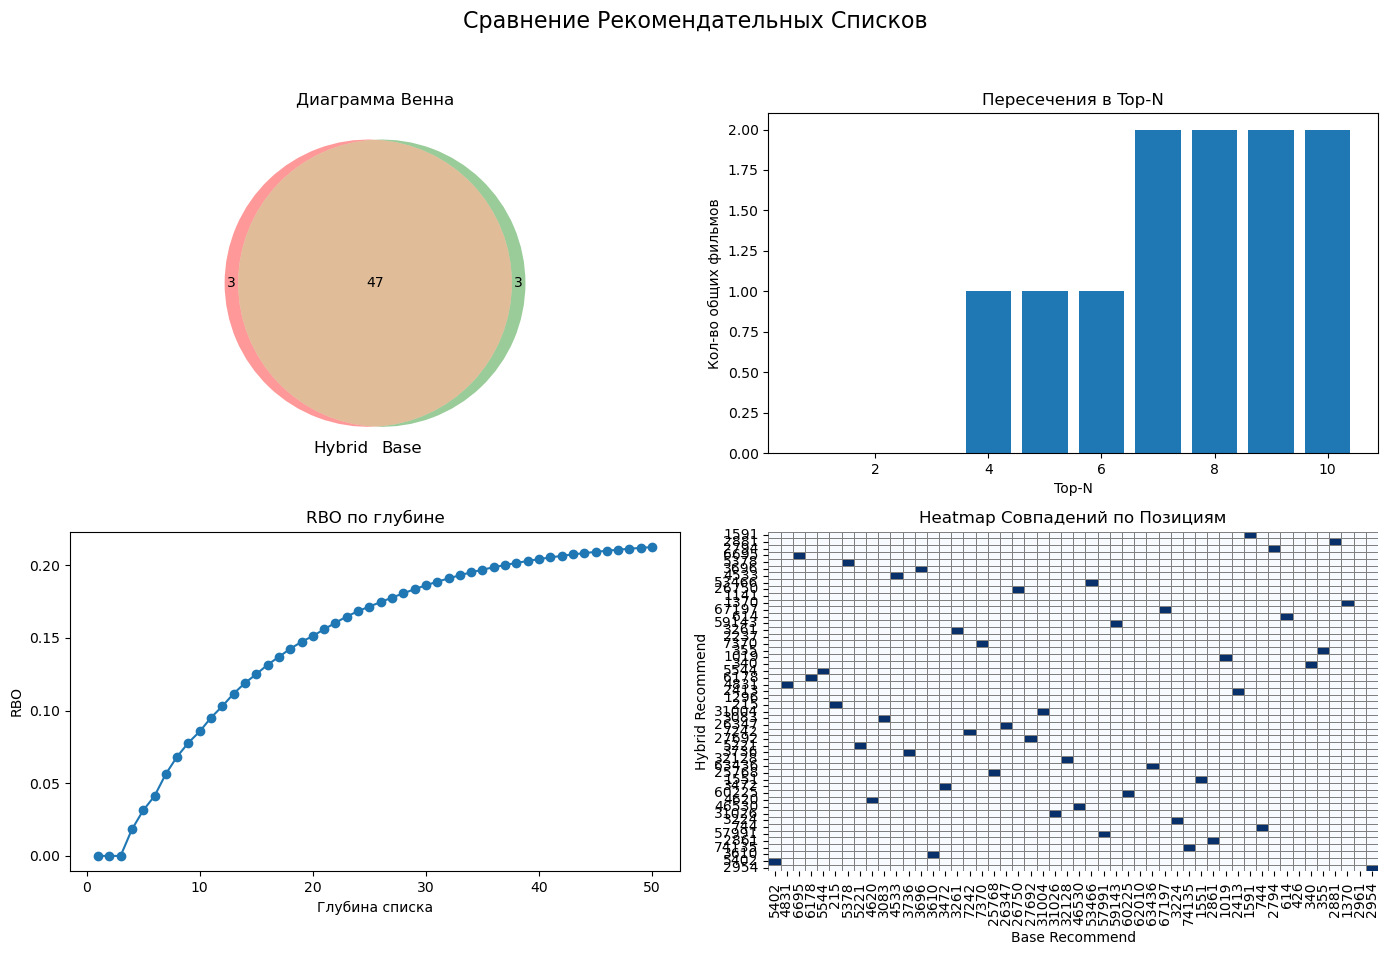

In [80]:
visualize_recommendations_df(recommend_movies, recommend_movies_test)

### Сравнение выдачи на обучающем векторе и обхединенном

In [33]:
combined_movie_content_vectors = np.concatenate(
    [movie_content_vectors_train, movie_content_vectors_test],
    axis=1  # объединяем по признакам
)

print("Финальный размер объединённого вектора:", combined_movie_content_vectors.shape)

Финальный размер объединённого вектора: (16376, 128)


In [40]:
# делаем новую кластеризациюя для общего вектора

n_clusters = 150
kmeans_movies_combine = KMeans(n_clusters=n_clusters, random_state=42, n_init='auto')
kmeans_movies_combine.fit(combined_movie_content_vectors)


KMeans(n_clusters=150, random_state=42)

In [41]:


# Для каждого тестового фильма получаем рекомендации, фильтруя по кластеру
recommend_movies_test_combine = recommend_movies_by_cluster_filtered(
    movie_ids=[1, 10, 100],  
    movie_content_vectors=combined_movie_vectors,
    movies_df=movies,
    kmeans_model=kmeans_movies_combine,
    top_n=50
)

Получаем рекомендации для фильма с ID: 1 (Название: Toy Story (1995)) (Жанры: Adventure|Animation|Children|Comedy|Fantasy)
Получаем рекомендации для фильма с ID: 10 (Название: GoldenEye (1995)) (Жанры: Action|Adventure|Thriller)
Получаем рекомендации для фильма с ID: 100 (Название: City Hall (1996)) (Жанры: Drama|Thriller)


In [42]:
# Сохраняем DataFrame
with open('content/films/combined_movie_vectors.dill', 'wb') as f:
    dill.dump(combined_movie_vectors, f)

In [18]:
with open('content/films/combined_movie_vectors.dill', 'rb') as f:
    combined_movie_vectors = dill.load(f)

In [43]:
recommend_movies_test_combine

,movie_id,title,genres,similarity_score,weight
15,1591,Spawn (1997),Action|Adventure|Sci-Fi|Thriller,0.384358,20.0
30,2881,Double Jeopardy (1999),Action|Crime|Drama|Thriller,0.361380,20.0
25,2794,European Vacation (aka National Lampoon's Euro...,Adventure|Comedy|Romance,0.340117,19.0
65,6695,Jeepers Creepers 2 (2003),Horror|Thriller,0.325643,19.0
57,5378,Star Wars: Episode II - Attack of the Clones (...,Action|Adventure|Sci-Fi|IMAX,0.309983,18.0
46,3696,Night of the Creeps (1986),Comedy|Horror|Sci-Fi|Thriller,0.291272,18.0
51,4533,"Return of the Living Dead, The (1985)",Comedy|Horror|Sci-Fi,0.275677,18.0
95,53466,Nancy Drew (2007),Adventure|Crime|Thriller,0.238106,17.0
80,26750,Quigley Down Under (1990),Adventure|Drama|Western,0.233572,17.0
10,1141,Last Call (Hoogste tijd) (1995),Drama,0.229195,17.0


Jaccard Similarity: 1.0
Precision@5: 1.0
Intersection Count: 50
RBO Score: 0.9948462247926795


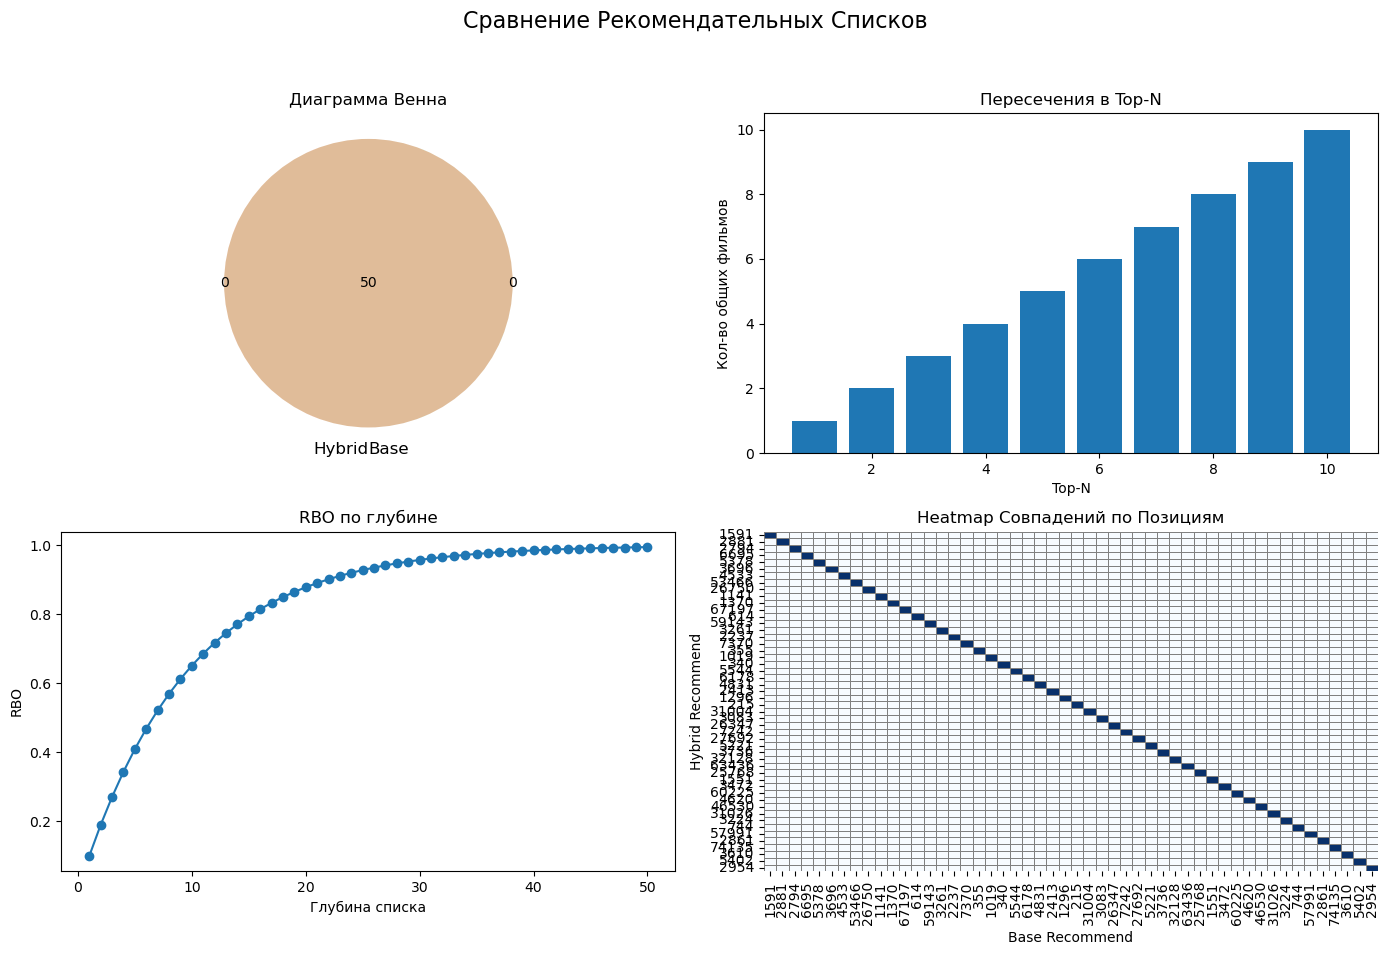

In [48]:
visualize_recommendations_df(recommend_movies, recommend_movies_test_combine)

✅ 1.Сравнение обучающего и тестового векторов по тэгам (train-tags vs test-tags):
- Jaccard Similarity: 0.89
- Precision@5: 0.2
- Intersection Count: 47
-и RBO Score: 0.2
🔍 Здесь уже модель знает про все фильмы (все строки), но:
У фильмов в train — только часть признаков (тэгов),
А в test — другая часть признаков.
📌 Это имитирует ситуацию, когда фильм сначала выходит с минимальной мета-информацией (жанры, базовые теги), а позже обогащается новыми данными (оценки пользователей, более точные тэги, дополнительные атрибуты и т.п.).
🧠 Это реалистичная ситуация "инкрементального обогащения контента".

⚠️ 2.  Сравнение обучающего и обобщенного (train vs combined):
- Jaccard Similarity: 1.0
- Precision@5: 1.0
- Intersection Count: 50
- RBO Score: 0.99

🔍 Это говорит о том, что добавление тестовых фильмов не влияло на топ-рекомендации вообще — модель просто рекомендовала всё то же самое, что и раньше. 

### 5.Функция продвижения/блокировки фильмов

In [53]:
# функция очистки таблицы продвижения/блокировки
def clear_importance_scores(movie_ids_to_promote=None, movie_ids_to_block=None, clear_all=False):
    """
    Очищает importance_df на основе списков фильмов для продвижения и блокировки.
    Если clear_all=True, очищает весь DataFrame.
    """
    global importance_df  # Обращаемся к глобальной переменной importance_df

    if clear_all:
        # Очищаем весь DataFrame
        importance_df = importance_df.iloc[0:0]  # Полностью очищаем DataFrame
        importance_df.reset_index(drop=True, inplace=True)  # Сбрасываем индексы
        return

    if movie_ids_to_promote:
        # Удаляем фильмы, которые были помечены для продвижения
        importance_df = importance_df[~importance_df['movie_id'].isin(movie_ids_to_promote)]

    if movie_ids_to_block:
        # Удаляем фильмы, которые были помечены для блокировки
        importance_df = importance_df[~importance_df['movie_id'].isin(movie_ids_to_block)]

    return importance_df
    

In [54]:
# функция добавления данных в таблицу продвижения/блокировки
def update_importance_scores(movie_ids_to_promote=None, movie_ids_to_block=None):
    """
    Обновляет importance_df на основе списков фильмов для продвижения и блокировки.
    """
    global importance_df

    if 'importance_df' not in globals():
        importance_df = pd.DataFrame(columns=['movieId', 'importance_score'])

    promote_df = pd.DataFrame({
        'movieId': movie_ids_to_promote or [],
        'importance_score': 1
    })

    block_df = pd.DataFrame({
        'movieId': movie_ids_to_block or [],
        'importance_score': -1
    })

    updated = pd.concat([importance_df, promote_df, block_df], ignore_index=True)
    importance_df = (
        updated.drop_duplicates('movieId', keep='last')  # Сохраняем последнюю установку
    )

In [55]:
update_importance_scores(movie_ids_to_promote=[10,100], movie_ids_to_block=[2550])


In [85]:
recommend_movies_test_combine = recommend_movies_by_cluster_filtered(
    movie_ids=[1, 10, 100],  
    movie_content_vectors=combined_movie_vectors,
    movies_df=movies,
    kmeans_model=kmeans_movies,
    top_n=50
)

Получаем рекомендации для фильма с ID: 1 (Название: Toy Story (1995)) (Жанры: Adventure|Animation|Children|Comedy|Fantasy)
Получаем рекомендации для фильма с ID: 10 (Название: GoldenEye (1995)) (Жанры: Action|Adventure|Thriller)
Получаем рекомендации для фильма с ID: 100 (Название: City Hall (1996)) (Жанры: Drama|Thriller)
Горячие новинки
--------------------------------------------------
  movieId             title                     genres
0      10  GoldenEye (1995)  Action|Adventure|Thriller
1     100  City Hall (1996)             Drama|Thriller


In [86]:
recommend_movies_test_combine

,movie_id,title,genres,similarity_score,weight
15,1591,Spawn (1997),Action|Adventure|Sci-Fi|Thriller,0.384358,20.0
30,2881,Double Jeopardy (1999),Action|Crime|Drama|Thriller,0.361380,20.0
25,2794,European Vacation (aka National Lampoon's Euro...,Adventure|Comedy|Romance,0.340117,19.0
65,6695,Jeepers Creepers 2 (2003),Horror|Thriller,0.325643,19.0
57,5378,Star Wars: Episode II - Attack of the Clones (...,Action|Adventure|Sci-Fi|IMAX,0.309983,18.0
46,3696,Night of the Creeps (1986),Comedy|Horror|Sci-Fi|Thriller,0.291272,18.0
51,4533,"Return of the Living Dead, The (1985)",Comedy|Horror|Sci-Fi,0.275677,18.0
95,53466,Nancy Drew (2007),Adventure|Crime|Thriller,0.238106,17.0
80,26750,Quigley Down Under (1990),Adventure|Drama|Western,0.233572,17.0
10,1141,Last Call (Hoogste tijd) (1995),Drama,0.229195,17.0


# Часть 2

### 7. Создаем матрицу взаимодействий


In [4]:
user_encoder = LabelEncoder()
user_encoder.fit(ratings['userId'])
joblib.dump(user_encoder, 'user_encoder.pkl')

item_encoder = LabelEncoder()
item_encoder.fit(ratings['movieId'])
joblib.dump(item_encoder, 'item_encoder.pkl')

# Применение энкодеров
user_encoder = joblib.load('user_encoder.pkl')
item_encoder = joblib.load('item_encoder.pkl')

ratings['user_idx'] = user_encoder.transform(ratings['userId'])
ratings['item_idx'] = item_encoder.transform(ratings['movieId'])

In [6]:
def split_interactions_by_user(ratings_df, test_size=0.2, min_interactions=2, random_state=42, chunk_size=10000):
    """
    Разделяет таблицу взаимодействий на train и test по каждому пользователю, с прогресс-баром и использованием меньших чанков.

    Parameters:
    - ratings_df: pd.DataFrame с колонками ['user_idx', 'item_idx', 'rating']
    - test_size: доля взаимодействий на тест (по каждому пользователю)
    - min_interactions: минимальное количество взаимодействий, при котором делается split
    - random_state: фиксированное зерно случайности
    - chunk_size: размер чанка для минимизации использования памяти при записи

    Returns:
    - ratings_train, ratings_test: два датафрейма с теми же колонками
    """
    train_chunks = []
    test_chunks = []
    
    # Индивидуальное разбиение по пользователям с прогресс-баром
    grouped = ratings_df.groupby('userId')

    for user_id, group in tqdm(grouped, desc="Разделение пользователей", total=len(grouped)):
        if len(group) < min_interactions:
            # Если у пользователя меньше минимальных взаимодействий, не разделяем на train/test
            train_chunks.append(group)
        else:
            if len(group) == min_interactions:
                # Если у пользователя ровно 2 взаимодействия, можно вручную разделить их
                train, test = group.iloc[:1], group.iloc[1:]  # 1 для train, 1 для test
            else:
                # Стандартное разбиение
                train, test = train_test_split(
                    group, test_size=test_size, random_state=random_state
                )
            
            train_chunks.append(train)
            test_chunks.append(test)

            # Если мы накопили достаточно данных, сбрасываем их в общий список
            if len(train_chunks) >= chunk_size:
                ratings_train = pd.concat(train_chunks).reset_index(drop=True)
                ratings_test = pd.concat(test_chunks).reset_index(drop=True)
                train_chunks = []  # очищаем для следующего чанка
                test_chunks = []

    # Записываем оставшиеся данные
    ratings_train = pd.concat(train_chunks).reset_index(drop=True)
    ratings_test = pd.concat(test_chunks).reset_index(drop=True)

    return ratings_train, ratings_test

In [13]:
ratings_train, ratings_test = split_interactions_by_user(ratings)
print(f"Train shape: {ratings_train.shape}, Test shape: {ratings_test.shape}")

Разделение пользователей: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 330975/330975 [04:12<00:00, 1311.77it/s]


Train shape: (83604, 6), Test shape: (21275, 6)


In [14]:
joblib.dump(ratings_train, "content/films/ratings_train.pkl")
joblib.dump(ratings_test, "content/films/ratings_test.pkl")

['content/films/ratings_test.pkl']

In [ ]:
# Загружаем
ratings_train = joblib.load('content/films/ratings_train.pkl')
ratings_test = joblib.load('content/films/ratings_test.pkl')

In [15]:
print(f"Создаем разреженныe матрицы ...")

# Создаем COO-матрицы
train_coo = coo_matrix(
    (ratings_train['rating'].astype(float),
     (ratings_train['user_idx'], ratings_train['item_idx']))
)

test_coo = coo_matrix(
    (ratings_test['rating'].astype(float),
     (ratings_test['user_idx'], ratings_test['item_idx']))
)

# CSR для ALS
train_csr = train_coo.tocsr()
test_csr = test_coo.tocsr()
print(f"train_csr shape: {train_csr.shape}, test_csr shape: {test_csr.shape}")

Создаем разреженныe матрицы ...
train_csr shape: (330975, 82894), test_csr shape: (330975, 82217)


### 8. C помощью Implicit ALS получаем из  матрицы взаимодействий item_factors

In [16]:
als_model = AlternatingLeastSquares(factors=64, regularization=0.1, iterations=15)
als_model.fit(train_coo.T)
# получаем эмбеддинги
item_factors_train = als_model.item_factors  # (num_items, 64)
user_factors_train = als_model.user_factors  # (num_users, 64)

/home/saatarko/.conda/envs/HomeworkDS/lib/python3.12/site-packages/implicit/cpu/als.py:95: RuntimeWarning: Intel MKL BLAS is configured to use 8 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'MKL_NUM_THREADS=1' or by callng 'threadpoolctl.threadpool_limits(1, "blas")'. Having MKL use a threadpool can lead to severe performance issues
  check_blas_config()
/home/saatarko/.conda/envs/HomeworkDS/lib/python3.12/site-packages/implicit/utils.py:164: ParameterWarning: Method expects CSR input, and was passed coo_matrix instead. Converting to CSR took 0.0008311271667480469 seconds
  warnings.warn(


  0%|          | 0/15 [00:00<?, ?it/s]

In [17]:
# Сохраняем
joblib.dump(als_model, 'content/films/als_model.joblib')
np.savez_compressed("content/films/item_factors_train.npz", vectors=item_factors_train)

In [7]:
# Загружаем
als_model = joblib.load('content/films/als_model.joblib')
data = np.load('content/films/item_factors_train.npz')
item_factors_train = data['vectors']

## 9. Подготовим чистый контент вектор

In [113]:
# Преобразуем genome_scores в широкую таблицу: movieId × tagId
movie_tag_matrix = genome_scores.pivot(index='movieId', columns='tagId', values='relevance').fillna(0)

# Добавим к movie_tag_matrix названия тегов
tag_id_to_name = genome_tags.set_index('tagId')['tag']
movie_tag_matrix.columns = movie_tag_matrix.columns.map(tag_id_to_name)

scaler_full_vector = MinMaxScaler()
movie_vectors_scaled = scaler_full_vector.fit_transform(movie_tag_matrix)


In [54]:
input_dim = movie_vectors_scaled.shape[1]  # 1128
encoding_dim = 64
batch_size = 256
num_epochs = 100
lr = 1e-3
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Преобразование данных в тензоры
X = torch.tensor(movie_vectors_scaled, dtype=torch.float32)

In [55]:
train_size = int(0.9 * len(X))
val_size = len(X) - train_size
train_dataset, val_dataset = random_split(X, [train_size, val_size])
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)

In [56]:
class MovieAutoencoder(nn.Module):
    def __init__(self, input_dim, encoding_dim):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, encoding_dim),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(encoding_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, input_dim),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)

In [57]:
model_movies_full = MovieAutoencoder(input_dim=input_dim, encoding_dim=encoding_dim).to(device)

In [59]:
optimizer = optim.Adam(model_movies_full.parameters(), lr=lr)
criterion = nn.MSELoss()

for epoch in range(num_epochs):
    model_movies_full.train()
    train_loss = 0
    for batch in train_loader:
        batch = batch.to(device)
        output = model_movies_full(batch)
        loss = criterion(output, batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    model_movies_full.eval()
    val_loss = 0
    with torch.no_grad():
        for batch in val_loader:
            batch = batch.to(device)
            output = model_movies_full(batch)
            loss = criterion(output, batch)
            val_loss += loss.item()

    print(f"Epoch [{epoch+1}/{num_epochs}] Train Loss: {train_loss/len(train_loader):.4f}, "
          f"Val Loss: {val_loss/len(val_loader):.4f}")

Epoch [1/100] Train Loss: 0.0461, Val Loss: 0.0285
Epoch [2/100] Train Loss: 0.0292, Val Loss: 0.0278
Epoch [3/100] Train Loss: 0.0273, Val Loss: 0.0186
Epoch [4/100] Train Loss: 0.0148, Val Loss: 0.0129
Epoch [5/100] Train Loss: 0.0124, Val Loss: 0.0116
Epoch [6/100] Train Loss: 0.0117, Val Loss: 0.0114
Epoch [7/100] Train Loss: 0.0113, Val Loss: 0.0106
Epoch [8/100] Train Loss: 0.0102, Val Loss: 0.0093
Epoch [9/100] Train Loss: 0.0092, Val Loss: 0.0088
Epoch [10/100] Train Loss: 0.0088, Val Loss: 0.0085
Epoch [11/100] Train Loss: 0.0086, Val Loss: 0.0083
Epoch [12/100] Train Loss: 0.0083, Val Loss: 0.0081
Epoch [13/100] Train Loss: 0.0081, Val Loss: 0.0079
Epoch [14/100] Train Loss: 0.0079, Val Loss: 0.0077
Epoch [15/100] Train Loss: 0.0077, Val Loss: 0.0075
Epoch [16/100] Train Loss: 0.0074, Val Loss: 0.0071
Epoch [17/100] Train Loss: 0.0071, Val Loss: 0.0068
Epoch [18/100] Train Loss: 0.0068, Val Loss: 0.0066
Epoch [19/100] Train Loss: 0.0066, Val Loss: 0.0064
Epoch [20/100] Train 

In [61]:
os.makedirs('content/films', exist_ok=True)
torch.save(model_movies_full.state_dict(), 'content/films/model_movies_full.pt')

In [ ]:
# При загрузке:
model_movies_full.load_state_dict(torch.load('content/films/model_movies_full.pt'))
model_movies_full.eval()

In [65]:
model_movies_full.eval()  # Переводим в режим инференса


with torch.no_grad():
    movie_vectors_tensor = torch.tensor(movie_vectors_scaled, dtype=torch.float32).to(device)
    model_movies_full_vectors = model_movies_full.encoder(movie_vectors_tensor).cpu().numpy()

print("Encoded vectors shape:", model_movies_full_vectors.shape)  # (16376, 64)


Encoded vectors shape: (16376, 64)


In [66]:
np.savez_compressed("content/films/movie_vectors_scaled.npz", vectors=model_movies_full_vectors)

In [ ]:
data = np.load('content/films/model_movies_full_vectors.npz')
model_movies_full_vectors = data['vectors']

## 10. Объединяем вектора

In [79]:
# movie_tag_matrix.index — это movieId'ы, соответствующие этому вектору
movie_ids_with_tags = movie_tag_matrix.index.to_numpy()

# Получаем индексы этих movieId'ов в item_matrix с помощью item_encoder
item_indices = item_encoder.transform(movie_ids_with_tags)

# Отбираем из item_matrix только нужные строки
filtered_item_matrix_train = item_factors_train[item_indices]

# Проверим:
print("Размерность model_movies_full_vectors:", model_movies_full_vectors.shape)
print("Размерность filtered_item_matrix_train:", filtered_item_matrix_train.shape)

# Объединяем по признакам (горизонтально)
hybrid_movie_vector = np.hstack([
    model_movies_full_vectors,
    filtered_item_matrix_train
])
print("Размерность объединённого вектора:", hybrid_movie_vector.shape)

Размерность model_movies_full_vectors: (16376, 64)
Размерность filtered_item_matrix_train: (16376, 64)
Размерность объединённого вектора: (16376, 128)


In [69]:
# Сохраняем
np.savez_compressed("content/films/recomend/hybrid_movie_vector.npz", vectors=hybrid_movie_vector)

In [8]:
# Загружаем
data = np.load('content/films/recomend/hybrid_movie_vector.npz')
hybrid_movie_vector = data['vectors']

### Делаем кластеризацию

In [70]:
n_clusters = 150
kmeans_hibrid = KMeans(n_clusters=n_clusters, random_state=42, n_init='auto')
kmeans_hibrid.fit(hybrid_movie_vector.astype(np.float64))

KMeans(n_clusters=150, random_state=42)

### Примеры работы системы рекомендации на простом гибридном векторе (на train als)

In [94]:
recommend_hybryd_movies= recommend_movies_by_cluster_filtered(
    movie_ids=[1, 10, 100],  
    movie_content_vectors=hybrid_movie_vector,
    movies_df=movies,
    kmeans_model=kmeans_hibrid,
    top_n=50
)

Получаем рекомендации для фильма с ID: 1 (Название: Toy Story (1995)) (Жанры: Adventure|Animation|Children|Comedy|Fantasy)
Получаем рекомендации для фильма с ID: 10 (Название: GoldenEye (1995)) (Жанры: Action|Adventure|Thriller)
Получаем рекомендации для фильма с ID: 100 (Название: City Hall (1996)) (Жанры: Drama|Thriller)


In [95]:
recommend_hybryd_movies

,movie_id,title,genres,similarity_score,weight
47,2881,Double Jeopardy (1999),Action|Crime|Drama|Thriller,0.380738,20.0
15,1591,Spawn (1997),Action|Adventure|Sci-Fi|Thriller,0.363099,20.0
42,2794,European Vacation (aka National Lampoon's Euro...,Adventure|Comedy|Romance,0.349347,19.0
75,5378,Star Wars: Episode II - Attack of the Clones (...,Action|Adventure|Sci-Fi|IMAX,0.310112,19.0
65,4533,"Return of the Living Dead, The (1985)",Comedy|Horror|Sci-Fi,0.305019,18.0
59,3696,Night of the Creeps (1986),Comedy|Horror|Sci-Fi|Thriller,0.278495,18.0
88,6695,Jeepers Creepers 2 (2003),Horror|Thriller,0.263240,18.0
131,67197,Knowing (2009),Action|Drama|Mystery|Sci-Fi|Thriller,0.246058,17.0
40,2762,"Sixth Sense, The (1999)",Drama|Horror|Mystery,0.209815,17.0
91,7370,A Foreign Affair (2003),Comedy|Drama|Romance,0.206235,17.0


In [56]:
### Набор метрик для расчета сходства реокмендаций

def precision_at_k(list1, list2, k=5):
    set1 = set(list1[:k])
    set2 = set(list2[:k])
    return len(set1 & set2) / k
    
def jaccard_similarity(list1, list2):
    set1 = set(list1)
    set2 = set(list2)
    return len(set1 & set2) / len(set1 | set2)

# def rbo_score(list1, list2, p=0.9):  # p — параметр затухания
#     return rbo.RankingSimilarity(list1, list2).rbo(p=p)

def intersection_count(list1, list2):
    return len(set(list1) & set(list2))

# Кол-во пересечений
def intersection_count(list1, list2):
    return len(set(list1) & set(list2))

# RBO Score
def rbo_score(list1, list2, p=0.9):
    """
    Вычисляет RBO (Rank Biased Overlap) для двух списков.
    p - параметр смещения (обычно в пределах от 0 до 1).
    """
    min_len = min(len(list1), len(list2))
    score = 0.0
    for i in range(min_len):
        score += (p ** i) * (list1[i] == list2[i])
    return score

# Top-N Пересечения
def top_n_intersections(list1, list2, top_n=10):
    return [len(set(list1[:i]) & set(list2[:i])) for i in range(1, top_n + 1)]

# Матрица совпадений для heatmap
def build_match_matrix(list1, list2):
    matrix = np.zeros((len(list1), len(list2)))
    for i, l1 in enumerate(list1):
        for j, l2 in enumerate(list2):
            if l1 == l2:
                matrix[i][j] = 1
    return matrix

### Сравниваем рекомендации от простой модели и гибридной (на train ALS)

In [53]:
def visualize_recommendations_df(df1, df2):
    list1 = df1['movie_id'].tolist()
    list2 = df2['movie_id'].tolist()

    set1 = set(list1)
    set2 = set(list2)
    
    ### Графическое сравнение
    # --- 1. Barplot Top-N Intersections ---
    def top_n_intersections(l1, l2, top_n=20):
        intersection_counts = []
        for n in range(1, top_n + 1):
            top1 = set(l1[:n])
            top2 = set(l2[:n])
            intersection_counts.append(len(top1 & top2))
        return intersection_counts
    
    # --- 3. Rank Biased Overlap ---
    def rbo_score(list1, list2, p=0.9):
        """Наивная реализация RBO."""
        score = 0.0
        depth = min(len(list1), len(list2))
        for d in range(1, depth + 1):
            set1 = set(list1[:d])
            set2 = set(list2[:d])
            overlap = len(set1 & set2)
            score += overlap / d * p ** (d - 1)
        return (1 - p) * score
    
    # --- 4. Heatmap of Position Matches ---
    def build_match_matrix(list1, list2):
        matrix = np.zeros((len(list1), len(list2)))
        for i, id1 in enumerate(list1):
            for j, id2 in enumerate(list2):
                if id1 == id2:
                    matrix[i, j] = 1
        return matrix

    print("Jaccard Similarity:", jaccard_similarity(list1, list2))
    print("Precision@5:", precision_at_k(list1, list2, k=5))
    print("Intersection Count:", intersection_count(list1, list2))
    print("RBO Score:", rbo_score(list1, list2))
    
    # Построение графиков
    fig, axs = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle("Сравнение Рекомендательных Списков", fontsize=16)
    
    # --- Venn Diagram ---
    venn2([set1, set2], set_labels=('Hybrid', 'Base'), ax=axs[0, 0])
    axs[0, 0].set_title("Диаграмма Венна")
    
    # --- Barplot Intersections ---
    intersection_counts = top_n_intersections(list1, list2, top_n=10)
    axs[0, 1].bar(range(1, 11), intersection_counts)
    axs[0, 1].set_title("Пересечения в Top-N")
    axs[0, 1].set_xlabel("Top-N")
    axs[0, 1].set_ylabel("Кол-во общих фильмов")
    
    # --- RBO Score Line ---
    rbo_scores = [rbo_score(list1[:k], list2[:k]) for k in range(1, min(len(list1), len(list2)) + 1)]
    axs[1, 0].plot(range(1, len(rbo_scores)+1), rbo_scores, marker='o')
    axs[1, 0].set_title("RBO по глубине")
    axs[1, 0].set_xlabel("Глубина списка")
    axs[1, 0].set_ylabel("RBO")
    
    # --- Heatmap ---
    match_matrix = build_match_matrix(list1, list2)
    sns.heatmap(match_matrix, cmap='Blues', cbar=False, ax=axs[1, 1],
                xticklabels=list2, yticklabels=list1, linewidths=0.5, linecolor='gray')
    axs[1, 1].set_title("Heatmap Совпадений по Позициям")
    axs[1, 1].set_xlabel("Base Recommend")
    axs[1, 1].set_ylabel("Hybrid Recommend")
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

Jaccard Similarity: 0.16279069767441862
Precision@5: 0.8
Intersection Count: 14
RBO Score: 0.6736394965190576


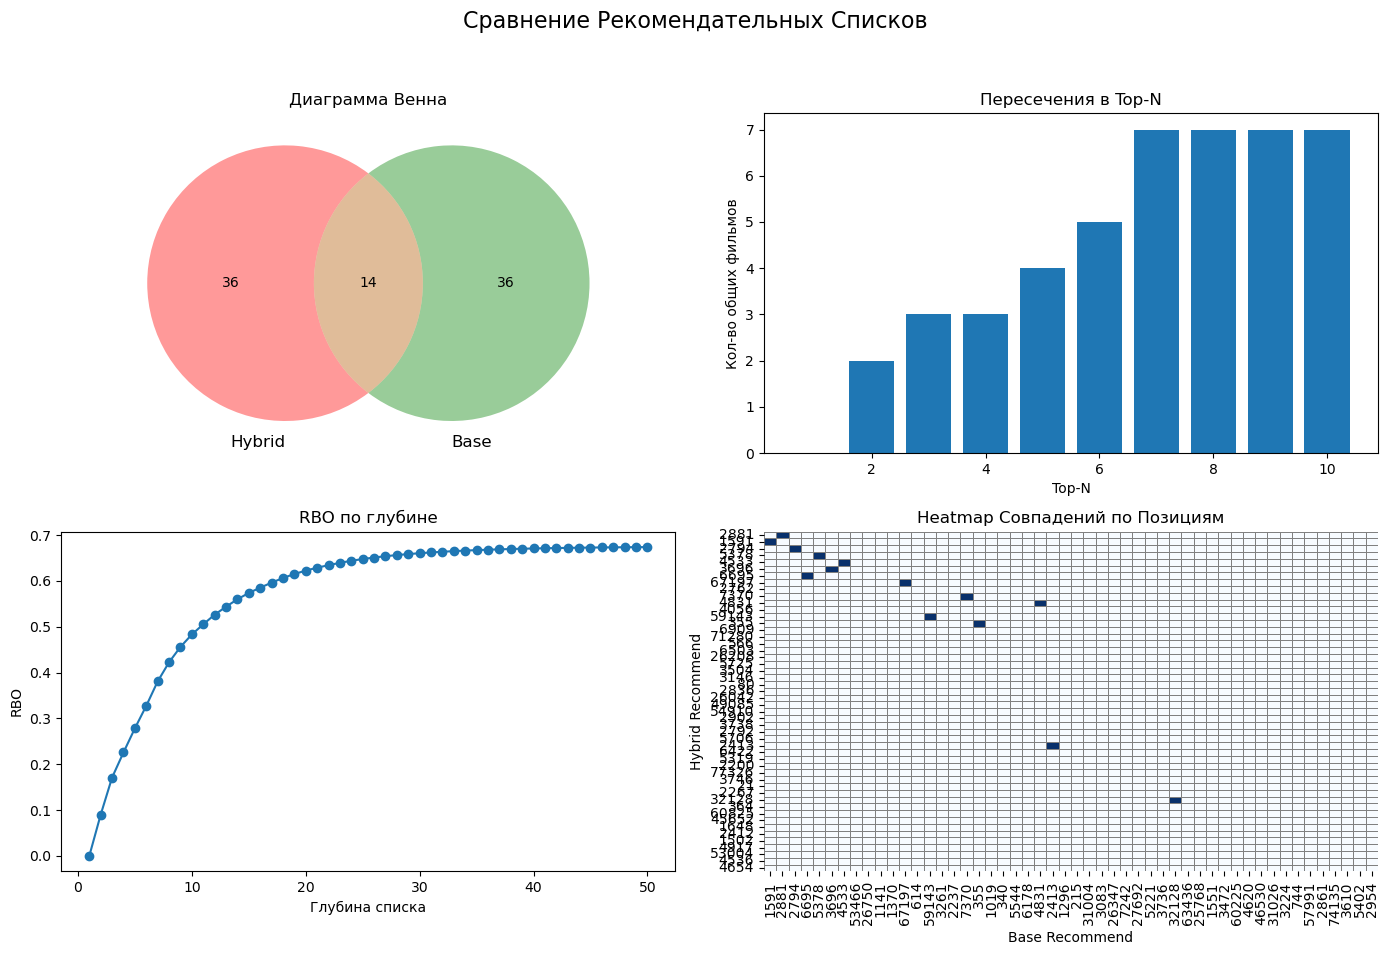

In [73]:
visualize_recommendations_df(recommend_hybryd_movies, recommend_movies)

### Выводы:
- Jaccard: 0.25 → 16% общих фильмов (по movie_id) среди двух списков.
- Precision@5: 0.8 → топ-4 рекомендаций из одного списка полностью попали в другой .
- Intersection Count: 14 → всего 20 фильмов пересеклись.
- RBO (Rank-Biased Overlap): ~0.67 → очень высокая близость по ранжированию. Отличный показатель.

💡 Это значит, что гибридный метод и обычный content-based не сильно расходятся — они хорошо согласуются в рекомендациях. Но при этом у каждого может быть своя "фишка", свои уникальные рекомендации

## 11. Оффлайн тестирование

### Создаем мост  item_factors с movies_vector

In [78]:
def train_bridge_models(X_content, Y_factors, verbose=True):
    models = []
    scores = []

    for i in tqdm(range(Y_factors.shape[1]), desc="Обучение bridge-моделей"):
        y = Y_factors[:, i]

        # Отладка: нет ли проблем с таргетом
        std_y = np.std(y)
        if std_y < 1e-4:
            if verbose:
                print(f"⚠️  Столбец {i}: std слишком мал ({std_y:.6f}) — регрессия бессмысленна.")
            models.append(None)
            scores.append({'r2': 0.0, 'mae': None, 'std_y': std_y})
            continue

        model = lgb.LGBMRegressor(
            n_estimators=100,
            learning_rate=0.1,
            num_leaves=31,
            min_data_in_leaf=5,
            min_gain_to_split=0.0,
            random_state=42
        )
        model.fit(X_content, y)
        y_pred = model.predict(X_content)

        r2 = r2_score(y, y_pred)
        mae = mean_absolute_error(y, y_pred)

        models.append(model)
        scores.append({'r2': r2, 'mae': mae, 'std_y': std_y})

        if verbose and r2 < 0.1:
            print(f"⚠️  Столбец {i}: низкий R² = {r2:.3f}, MAE = {mae:.3f}, std_y = {std_y:.3f}")

    return models, scores

In [80]:
models_bridge, quality_report = train_bridge_models(
    model_movies_full_vectors,
    filtered_item_matrix_train
)


Обучение bridge-моделей: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 64/64 [00:00<00:00, 3742.51it/s]

⚠️  Столбец 0: std слишком мал (0.000000) — регрессия бессмысленна.
⚠️  Столбец 1: std слишком мал (0.000000) — регрессия бессмысленна.
⚠️  Столбец 2: std слишком мал (0.000000) — регрессия бессмысленна.
⚠️  Столбец 3: std слишком мал (0.000000) — регрессия бессмысленна.
⚠️  Столбец 4: std слишком мал (0.000000) — регрессия бессмысленна.
⚠️  Столбец 5: std слишком мал (0.000000) — регрессия бессмысленна.
⚠️  Столбец 6: std слишком мал (0.000000) — регрессия бессмысленна.
⚠️  Столбец 7: std слишком мал (0.000000) — регрессия бессмысленна.
⚠️  Столбец 8: std слишком мал (0.000000) — регрессия бессмысленна.
⚠️  Столбец 9: std слишком мал (0.000000) — регрессия бессмысленна.
⚠️  Столбец 10: std слишком мал (0.000000) — регрессия бессмысленна.
⚠️  Столбец 11: std слишком мал (0.000000) — регрессия бессмысленна.
⚠️  Столбец 12: std слишком мал (0.000000) — регрессия бессмысленна.
⚠️  Столбец 13: std слишком мал (0.000000) — регрессия бессмысленна.
⚠️  Столбец 14: std слишком мал (0.000000) —

In [82]:
def predict_item_factors_batch(content_vectors, models_bridge):
    """
    Предсказывает item_factors для нескольких фильмов на основе их content_vectors.
    
    :param content_vectors: np.array формы (N, 64) — контентные векторы фильмов
    :param models_bridge: список из LGBM-моделей (или None для невалидных колонок)
    :return: np.array формы (N, 64) — предсказанные item_factors
    """
    content_vectors = np.asarray(content_vectors)  # (N, 64)
    n_samples = content_vectors.shape[0]
    n_factors = len(models_bridge)

    predictions = np.zeros((n_samples, n_factors))

    for i, model in enumerate(models_bridge):
        if model is not None:
            predictions[:, i] = model.predict(content_vectors)
        else:
            # Заполняем нулями колонку, если модель не обучалась
            predictions[:, i] = 0.0

    return predictions

In [57]:
# Сохранение
for i, model_bridge in enumerate(models_bridge):
    joblib.dump(model_bridge, f"content/films/recomend/lgb_model_component_{i}.pkl")

In [106]:
# Загрузка
models_bridge = [joblib.load(f"content/films/recomend/lgb_model_component_{i}.pkl") for i in range(64)]  # где num_factors = dim ALS векторов

### Вывод: Пользователи и фильмы неперекрывающиеся или взаимодействий недостаточно, чтобы item_factors адекватно обучились. Поэтому провернуть офланй тестирование на гибридном векторе - не получится. Значит делаем полный гибридный вектор

In [83]:
user_encoder = LabelEncoder()
user_encoder.fit(ratings['userId'])
joblib.dump(user_encoder, 'user_encoder.pkl')

item_encoder = LabelEncoder()
item_encoder.fit(ratings['movieId'])
joblib.dump(item_encoder, 'item_encoder.pkl')

# Применение энкодеров
user_encoder = joblib.load('user_encoder.pkl')
item_encoder = joblib.load('item_encoder.pkl')

ratings['user_idx'] = user_encoder.transform(ratings['userId'])
ratings['item_idx'] = item_encoder.transform(ratings['movieId'])

print(f"Создаем разреженную матрицу ...")

ratings_coo = coo_matrix(
    (ratings['rating'].astype(float), (ratings['user_idx'], ratings['item_idx']))
)

ratings_csr = ratings_coo.tocsr()  # CSR формат
ratings_csr.shape

Создаем разреженную матрицу ...


(330975, 83239)

In [99]:
als_model_full = AlternatingLeastSquares(factors=64, regularization=0.1, iterations=15)
als_model_full.fit(ratings_csr.T)
item_factors_full = als_model_full.item_factors  # shape: (83239, 64)

/home/saatarko/.conda/envs/HomeworkDS/lib/python3.12/site-packages/implicit/utils.py:164: ParameterWarning: Method expects CSR input, and was passed csc_matrix instead. Converting to CSR took 0.4987010955810547 seconds
  warnings.warn(


  0%|          | 0/15 [00:00<?, ?it/s]

In [100]:
# Сохраняем
joblib.dump(als_model, 'content/films/als_model_full.joblib')
np.savez_compressed("content/films/item_factors_full.npz", vectors=item_factors_full)

In [ ]:
# Загружаем
als_model_full = joblib.load('content/films/als_model_full.joblib')
data = np.load('content/films/item_factors_full.npz')
item_factors_train = data['vectors']

In [101]:
# movie_tag_matrix.index — это movieId'ы, соответствующие этому вектору
movie_ids_with_tags = movie_tag_matrix.index.to_numpy()

# Получаем индексы этих movieId'ов в item_matrix с помощью item_encoder
item_indices = item_encoder.transform(movie_ids_with_tags)

# Отбираем из item_matrix только нужные строки
filtered_item_matrix_full = item_factors_full[item_indices]

# Проверим:
print("Размерность model_movies_full_vectors:", model_movies_full_vectors.shape)
print("Размерность filtered_item_matrix_train:", filtered_item_matrix_full.shape)

# Объединяем по признакам (горизонтально)
hybrid_movie_vector_full = np.hstack([
    model_movies_full_vectors,
    filtered_item_matrix_full
])
print("Размерность объединённого вектора:", hybrid_movie_vector_full.shape)

Размерность model_movies_full_vectors: (16376, 64)
Размерность filtered_item_matrix_train: (16376, 64)
Размерность объединённого вектора: (16376, 128)


In [102]:
n_clusters = 150
kmeans_hibrid_full = KMeans(n_clusters=n_clusters, random_state=42, n_init='auto')
kmeans_hibrid_full.fit(hybrid_movie_vector_full.astype(np.float64))

KMeans(n_clusters=150, random_state=42)

In [103]:
# Сохраняем
joblib.dump(kmeans_hibrid_full, 'content/films/kmeans_hibrid_full.joblib')

['content/films/kmeans_hibrid_full.joblib']

In [ ]:
# Загружаем
kmeans_hibrid_full = joblib.load('content/films/kmeans_hibrid_full.joblib')

In [104]:
recommend_hybryd_movies_full= recommend_movies_by_cluster_filtered(
    movie_ids=[1, 10, 100],  
    movie_content_vectors=hybrid_movie_vector_full,
    movies_df=movies,
    kmeans_model=kmeans_hibrid_full,
    top_n=50
)

Получаем рекомендации для фильма с ID: 1 (Название: Toy Story (1995)) (Жанры: Adventure|Animation|Children|Comedy|Fantasy)
Получаем рекомендации для фильма с ID: 10 (Название: GoldenEye (1995)) (Жанры: Action|Adventure|Thriller)
Получаем рекомендации для фильма с ID: 100 (Название: City Hall (1996)) (Жанры: Drama|Thriller)


In [105]:
recommend_hybryd_movies_full

,movie_id,title,genres,similarity_score,weight
29,2881,Double Jeopardy (1999),Action|Crime|Drama|Thriller,0.371459,20.0
11,1591,Spawn (1997),Action|Adventure|Sci-Fi|Thriller,0.357110,20.0
24,2794,European Vacation (aka National Lampoon's Euro...,Adventure|Comedy|Romance,0.343958,19.0
54,5378,Star Wars: Episode II - Attack of the Clones (...,Action|Adventure|Sci-Fi|IMAX,0.306569,19.0
44,4533,"Return of the Living Dead, The (1985)",Comedy|Horror|Sci-Fi,0.302845,18.0
39,3696,Night of the Creeps (1986),Comedy|Horror|Sci-Fi|Thriller,0.274806,18.0
73,6695,Jeepers Creepers 2 (2003),Horror|Thriller,0.260804,18.0
143,67197,Knowing (2009),Action|Drama|Mystery|Sci-Fi|Thriller,0.244022,17.0
10,1370,Die Hard 2 (1990),Action|Adventure|Thriller,0.212948,17.0
118,44881,Keane (2004),Mystery|Thriller,0.206188,17.0


### Сравниваем рекомендации от гибридной модели (на train ALS) и полной гибридной модели

Jaccard Similarity: 0.17647058823529413
Precision@5: 1.0
Intersection Count: 15
RBO Score: 0.8576069291765455


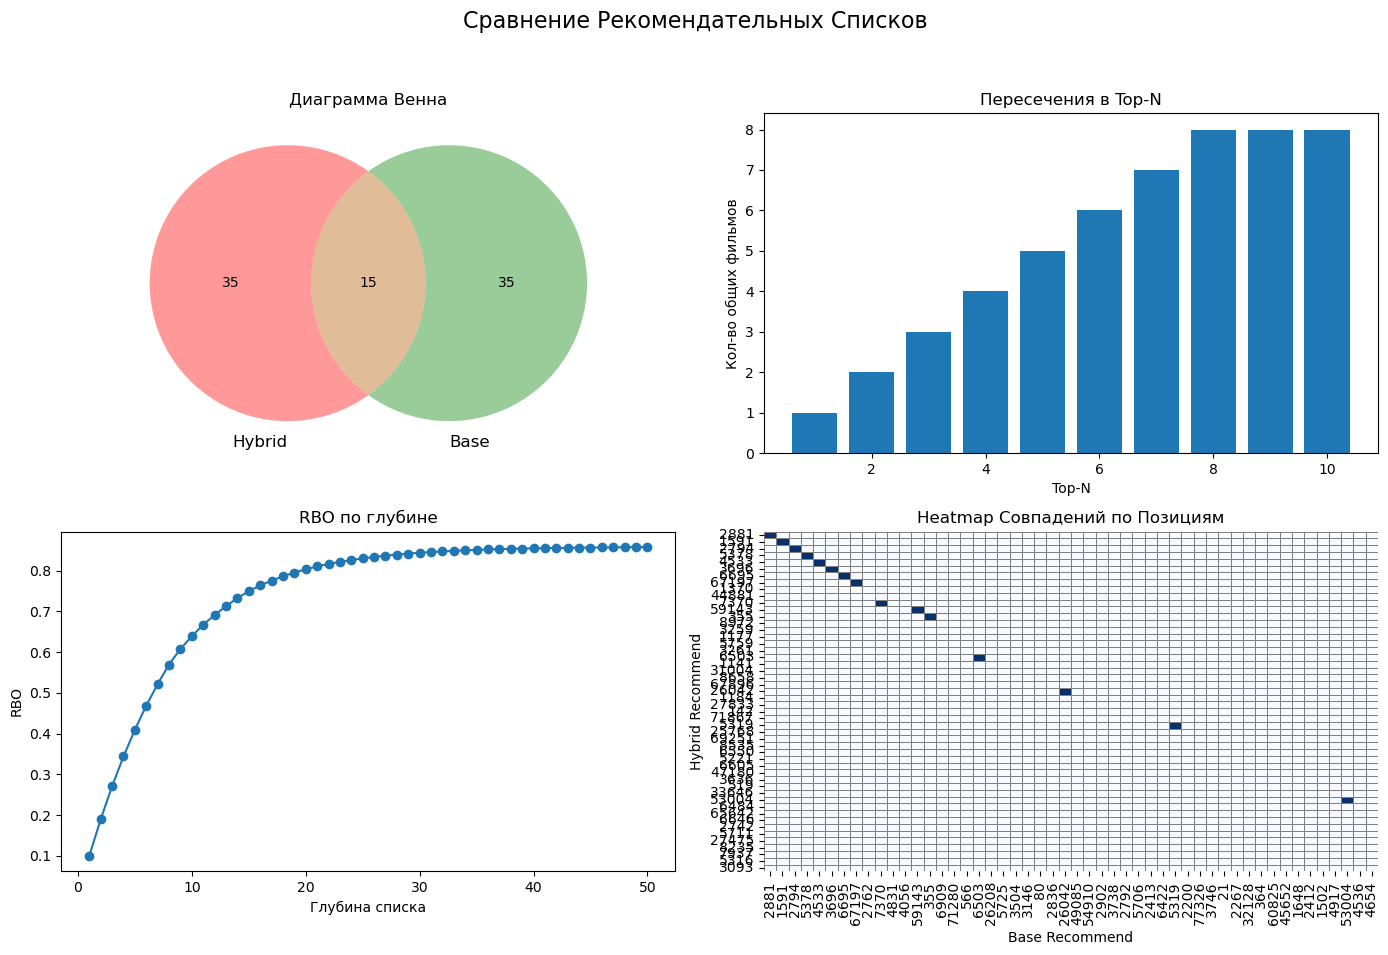

In [106]:
visualize_recommendations_df(recommend_hybryd_movies_full, recommend_hybryd_movies)

### Добавление нового фильма к гибридной рекомендательной системе

### Создаем мост item_factors с movies_vector

In [107]:
models_bridge, quality_report = train_bridge_models(
    model_movies_full_vectors,
    filtered_item_matrix_full
)

Обучение bridge-моделей:   0%|                                                                                                                                                                                                                                                               | 0/64 [00:00<?, ?it/s]

[LightGBM] [Warning] min_data_in_leaf is set=5, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=5
[LightGBM] [Warning] min_gain_to_split is set=0.0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.0
[LightGBM] [Warning] min_data_in_leaf is set=5, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=5
[LightGBM] [Warning] min_gain_to_split is set=0.0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.0
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001914 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7395
[LightGBM] [Info] Number of data points in the train set: 16376, number of used features: 29
[LightGBM] [Info] Start training from score 0.003876


Обучение bridge-моделей:   3%|███████▋                                                                                                                                                                                                                                               | 2/64 [00:00<00:11,  5.62it/s]

[LightGBM] [Warning] min_gain_to_split is set=0.0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.0
[LightGBM] [Warning] min_data_in_leaf is set=5, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=5
[LightGBM] [Warning] min_data_in_leaf is set=5, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=5
[LightGBM] [Warning] min_gain_to_split is set=0.0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.0
[LightGBM] [Warning] min_data_in_leaf is set=5, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=5
[LightGBM] [Warning] min_gain_to_split is set=0.0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.0
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001405 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7395
[LightGBM] [Info] Number of data points in the train set: 16376, number 

Обучение bridge-моделей:   6%|███████████████▍                                                                                                                                                                                                                                       | 4/64 [00:00<00:09,  6.53it/s]

...

[LightGBM] [Warning] min_gain_to_split is set=0.0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.0
[LightGBM] [Warning] min_data_in_leaf is set=5, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=5
[LightGBM] [Warning] min_data_in_leaf is set=5, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=5
[LightGBM] [Warning] min_gain_to_split is set=0.0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.0
[LightGBM] [Warning] min_data_in_leaf is set=5, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=5
[LightGBM] [Warning] min_gain_to_split is set=0.0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.0
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001345 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7395
[LightGBM] [Info] Number of data points in the train set: 16376, number 

Обучение bridge-моделей:  97%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▎       | 62/64 [00:09<00:00,  6.58it/s]

[LightGBM] [Warning] min_data_in_leaf is set=5, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=5
[LightGBM] [Warning] min_gain_to_split is set=0.0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.0
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001041 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7395
[LightGBM] [Info] Number of data points in the train set: 16376, number of used features: 29
[LightGBM] [Info] Start training from score 0.002375
[LightGBM] [Warning] min_gain_to_split is set=0.0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.0
[LightGBM] [Warning] min_data_in_leaf is set=5, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=5
[LightGBM] [Warning] min_data_in_leaf is set=5, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=5
[LightGBM] [Warning] min_gain_to_split is set=0.0,

Обучение bridge-моделей: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 64/64 [00:10<00:00,  6.28it/s]

[LightGBM] [Warning] min_gain_to_split is set=0.0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.0
[LightGBM] [Warning] min_data_in_leaf is set=5, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=5
[LightGBM] [Warning] min_data_in_leaf is set=5, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=5
[LightGBM] [Warning] min_gain_to_split is set=0.0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.0
[LightGBM] [Warning] min_data_in_leaf is set=5, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=5
[LightGBM] [Warning] min_gain_to_split is set=0.0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.0
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000863 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7395
[LightGBM] [Info] Number of data points in the train set: 16376, number 

In [108]:
# Сохраняем
joblib.dump(models_bridge, 'content/films/models_bridge.joblib')

['content/films/models_bridge.joblib']

In [ ]:
# Загружаем
models_bridge = joblib.load('content/films/models_bridge.joblib')

In [ ]:
def predict_item_factors_batch(content_vectors, models_bridge):
    """
    Предсказывает item_factors для нескольких фильмов на основе их content_vectors.
    
    :param content_vectors: np.array формы (N, 64) — контентные векторы фильмов
    :param models_bridge: список из LGBM-моделей (или None для невалидных колонок)
    :return: np.array формы (N, 64) — предсказанные item_factors
    """
    content_vectors = np.asarray(content_vectors)  # (N, 64)
    n_samples = content_vectors.shape[0]
    n_factors = len(models_bridge)

    predictions = np.zeros((n_samples, n_factors))

    for i, model in enumerate(models_bridge):
        if model is not None:
            predictions[:, i] = model.predict(content_vectors)
        else:
            # Заполняем нулями колонку, если модель не обучалась
            predictions[:, i] = 0.0

    return predictions

In [124]:
def add_new_movie_and_predict_cluster(new_movie_id, new_movie_title, new_movie_genres, original_movie_vector, 
                                       item_encoder, item_factors, models_bridge, hybrid_movie_vectors, 
                                       movies, kmeans_model, model_movies):
    # Предсказание item факторов для нового фильма (предполагаем, что вектор уже получен)
    predicted_item_factors = predict_item_factors_batch(original_movie_vector, models_bridge)
    
    # Создаем гибридный вектор для нового фильма
    hybrid_vector = np.hstack([original_movie_vector, predicted_item_factors])
    
    # Обновляем гибридные векторы
    updated_hybrid_movie_vectors = np.vstack([hybrid_movie_vectors, hybrid_vector])
    
    # Получаем кластер для нового фильма
    new_movie_cluster = kmeans_model.predict(hybrid_vector.reshape(1, -1))[0]

    
    # Создаем новый фильм
    new_movie = {'movieId': new_movie_id, 'title': new_movie_title, 'genres': new_movie_genres}
    
    # Обновляем DataFrame, добавляя новый фильм
    updated_movies_df = pd.concat([movies, pd.DataFrame([new_movie])], ignore_index=True)
    
    return updated_movies_df, updated_hybrid_movie_vectors, new_movie_cluster

### Добавление флиьма на основе сущетсвующего

In [125]:
# Параметры для нового фильма
new_movie_id = movies['movieId'].max() + 1  # Новый movieId будет максимальным + 1
new_movie_title = "Test"
new_movie_genres = 'Drama|Romance'  # Жанры для нового фильма

# Извлекаем строку фильма с ID 27475 из movie_tag_matrix
original_movie_vector = movie_tag_matrix.loc[6695].values  # Берем вектор для фильма из movie_tag_matrix

# Применяем тот же скейлер, что использовался для других фильмов
scaled_new_movie_data = scaler_full_vector.transform([original_movie_vector])

# Получаем контентный вектор для нового фильма через автоэнкодер
new_movie_vector = model_movies_full.encoder(torch.tensor(scaled_new_movie_data, dtype=torch.float32).to(device)).cpu().detach().numpy()

/home/saatarko/.conda/envs/HomeworkDS/lib/python3.12/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


In [126]:
updated_movies_df, updated_hybrid_movie_vectors, new_movie_cluster = add_new_movie_and_predict_cluster(
    new_movie_id, 
    new_movie_title, 
    new_movie_genres, 
    new_movie_vector,
    item_encoder, 
    item_factors_full, 
    models_bridge, 
    hybrid_movie_vector_full, 
    movies, 
    kmeans_hibrid_full, 
    model_movies_full
)

[LightGBM] [Warning] min_gain_to_split is set=0.0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.0
[LightGBM] [Warning] min_data_in_leaf is set=5, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=5
[LightGBM] [Warning] min_gain_to_split is set=0.0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.0
[LightGBM] [Warning] min_data_in_leaf is set=5, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=5
[LightGBM] [Warning] min_gain_to_split is set=0.0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.0
[LightGBM] [Warning] min_data_in_leaf is set=5, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=5
[LightGBM] [Warning] min_gain_to_split is set=0.0, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.0
[LightGBM] [Warning] min_data_in_leaf is set=5, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=5
[LightGBM] [Warning] min

## 12. Добавление новго фильма

In [ ]:
# Параметры для нового фильма
new_movie_id = movies['movieId'].max() + 1  # Новый movieId будет максимальным + 1
new_movie_title = "Test"
new_movie_genres = 'Drama|Romance'  # Жанры для нового фильма

# Получаем контентный вектор для нового фильма через функцию
updated_movies_df, updated_hybrid_movie_vectors, new_movie_cluster = add_new_movie_and_predict_cluster(
    new_movie_id, 
    new_movie_title, 
    new_movie_genres, 
    None,  # Мы не передаем оригинальный вектор, так как он будет генерироваться внутри функции
    item_encoder, 
    item_factors_full, 
    models_bridge, 
    hybrid_movie_vector_full, 
    movies, 
    kmeans_hibrid_full, 
    model_movies_full
)

### Пример рекомендаций после добавления нового фильма в базу

In [127]:
recommend_new_movies= recommend_movies_by_cluster_filtered(
    movie_ids=[1, 10, 100],  
    movie_content_vectors=updated_hybrid_movie_vectors,
    movies_df=updated_movies_df,
    kmeans_model=kmeans_hibrid_full,
    top_n=50
)

Получаем рекомендации для фильма с ID: 1 (Название: Toy Story (1995)) (Жанры: Adventure|Animation|Children|Comedy|Fantasy)
Получаем рекомендации для фильма с ID: 10 (Название: GoldenEye (1995)) (Жанры: Action|Adventure|Thriller)
Получаем рекомендации для фильма с ID: 100 (Название: City Hall (1996)) (Жанры: Drama|Thriller)


In [128]:
recommend_new_movies

,movie_id,title,genres,similarity_score,weight
29,2881,Double Jeopardy (1999),Action|Crime|Drama|Thriller,0.371459,20.0
11,1591,Spawn (1997),Action|Adventure|Sci-Fi|Thriller,0.357110,20.0
24,2794,European Vacation (aka National Lampoon's Euro...,Adventure|Comedy|Romance,0.343958,19.0
54,5378,Star Wars: Episode II - Attack of the Clones (...,Action|Adventure|Sci-Fi|IMAX,0.306569,19.0
44,4533,"Return of the Living Dead, The (1985)",Comedy|Horror|Sci-Fi,0.302845,18.0
39,3696,Night of the Creeps (1986),Comedy|Horror|Sci-Fi|Thriller,0.274806,18.0
73,6695,Jeepers Creepers 2 (2003),Horror|Thriller,0.260804,18.0
143,67197,Knowing (2009),Action|Drama|Mystery|Sci-Fi|Thriller,0.244022,17.0
10,1370,Die Hard 2 (1990),Action|Adventure|Thriller,0.212948,17.0
118,44881,Keane (2004),Mystery|Thriller,0.206188,17.0


In [131]:
def recommend_movies_by_cluster_filtered_new(
    movie_ids,
    movie_content_vectors,
    movies_df,
    kmeans_model,
    top_n=50
):
    cluster_labels = kmeans_model.labels_
    all_recommendations = []

    for movie_id in movie_ids:
        try:
            movie_row = movies_df[movies_df['movieId'] == movie_id]
            if movie_row.empty:
                print(f"[!] Фильм с ID {movie_id} не найден в базе.")
                continue

            movie_idx = movie_row.index[0]

            # Защита от выхода за границы массива векторов
            if movie_idx >= len(movie_content_vectors):
                movie_idx = len(movie_content_vectors) - 1

            movie_title = movie_row.iloc[0]['title']
            movie_genres = movie_row.iloc[0]['genres']
            genres_set = set(movie_genres.split('|'))

            print(f"Получаем рекомендации для фильма с ID: {movie_id} (Название: {movie_title}) (Жанры: {movie_genres})")

            # Предсказываем кластер
            cluster_label = kmeans_model.predict([movie_content_vectors[movie_idx]])[0]
            same_cluster_indices = np.where(kmeans_model.labels_ == cluster_label)[0]
            same_cluster_indices = [idx for idx in same_cluster_indices if idx != movie_idx]

            if not same_cluster_indices:
                print(f"[!] Кластер пуст для фильма {movie_id}")
                continue

            distances = euclidean_distances(
                movie_content_vectors[movie_idx].reshape(1, -1),
                movie_content_vectors[same_cluster_indices]
            )[0]
            similarities = 1 / (1 + distances)

            for idx, score in zip(same_cluster_indices, similarities):
                title = movies_df.iloc[idx]['title']
                genres = movies_df.iloc[idx]['genres']
                genres_set_target = set(genres.split('|'))

                if pd.isna(title) or pd.isna(genres):
                    continue

                if not genres_set.intersection(genres_set_target):
                    score = 0  # Фильтрация по жанрам

                all_recommendations.append({
                    'movie_id': movies_df.iloc[idx]['movieId'],
                    'title': title,
                    'genres': genres,
                    'similarity_score': score
                })

        except Exception as e:
            print(f"[!] Ошибка при обработке movie_id={movie_id}: {e}")
            continue

    all_recommendations_df = pd.DataFrame(all_recommendations)
    if all_recommendations_df.empty:
        print("[!] Нет рекомендаций")
        return all_recommendations_df

    # Суммируем по фильмам
    all_recommendations_df = all_recommendations_df.groupby(
        ['movie_id', 'title', 'genres']
    ).agg({'similarity_score': 'sum'}).reset_index()

    # Удаляем заблокированные фильмы
    drop_film = importance_df[importance_df['importance_score'] == -1]['movieId'].astype(int)
    filtered_recs = all_recommendations_df[~all_recommendations_df['movie_id'].isin(drop_film)]

    # Сортировка и веса
    filtered_recs = filtered_recs.sort_values('similarity_score', ascending=False).head(top_n)
    weights = np.linspace(20, 1, len(filtered_recs)).round()
    filtered_recs['weight'] = weights

    # Отображение "горячих новинок"
    temp_list = importance_df[importance_df['importance_score'] == 1].rename(columns={'movie_id': 'movieId'})
    temp_list = temp_list.merge(movies_df[['movieId', 'title', 'genres']], on='movieId', how='left').dropna(subset=['title', 'genres'])

    if len(temp_list) != 0:
        print('Горячие новинки')
        print('-' * 50)
        print(temp_list[['movieId', 'title', 'genres']])

    return filtered_recs

In [135]:
recommend_new_movies = recommend_movies_by_cluster_filtered_new(
    movie_ids=[288984],
    movie_content_vectors=updated_hybrid_movie_vectors,
    movies_df=updated_movies_df,
    kmeans_model=kmeans_hibrid_full,
    top_n=10
)

Получаем рекомендации для фильма с ID: 288984 (Название: Test) (Жанры: Drama|Romance)


In [136]:
recommend_new_movies

,movie_id,title,genres,similarity_score,weight
45,2352,"Big Chill, The (1983)",Comedy|Drama,0.293743,20.0
29,1850,"I Love You, Don't Touch Me! (1998)",Drama|Romance,0.262785,18.0
125,55247,Into the Wild (2007),Action|Adventure|Drama,0.259348,16.0
23,1842,Illtown (1996),Crime|Drama,0.258954,14.0
9,1586,G.I. Jane (1997),Action|Drama,0.253848,12.0
96,26158,Closely Watched Trains (Ostre sledované vlaky)...,Comedy|Drama|War,0.252084,9.0
44,2351,"Nights of Cabiria (Notti di Cabiria, Le) (1957)",Drama,0.251821,7.0
129,64114,Fireproof (2008),Drama|Romance,0.248441,5.0
113,39307,Dreamer: Inspired by a True Story (2005),Children|Drama,0.248263,3.0
16,1832,Heaven's Burning (1997),Action|Drama,0.248033,1.0


In [141]:
recommend_new_movies

,movie_id,title,genres,similarity_score,weight
44,2351,"Nights of Cabiria (Notti di Cabiria, Le) (1957)",Drama,0.877471,20.0
5,1224,Henry V (1989),Action|Drama|Romance|War,0.848917,20.0
78,5236,"Tale of Springtime, A (Conte de Printemps) (1990)",Drama|Romance,0.840255,19.0
113,39307,Dreamer: Inspired by a True Story (2005),Children|Drama,0.837957,19.0
1,583,Dear Diary (Caro Diario) (1994),Comedy|Drama,0.828145,18.0
23,1842,Illtown (1996),Crime|Drama,0.811317,18.0
39,2293,Shadrach (1998),Drama,0.809921,18.0
4,1027,Robin Hood: Prince of Thieves (1991),Adventure|Drama,0.809590,17.0
19,1835,City of Angels (1998),Drama|Fantasy|Romance,0.797588,17.0
14,1829,Chinese Box (1997),Drama|Romance,0.792917,17.0


### Вывод: Рекомендации работает для нового фильма. А то что он не выдался (как мы хотели) в общей выдачи связано с тем что нам не удалось создать похожий вектор для попадания в список 

# Часть 3.

## 13. Понижаем размерность матрицы взаимодействий encoder-ом

In [4]:
user_encoder = LabelEncoder()
user_encoder.fit(ratings['userId'])
joblib.dump(user_encoder, 'user_encoder.pkl')

item_encoder = LabelEncoder()
item_encoder.fit(ratings['movieId'])
joblib.dump(item_encoder, 'item_encoder.pkl')

# Применение энкодеров
user_encoder = joblib.load('user_encoder.pkl')
item_encoder = joblib.load('item_encoder.pkl')

ratings['user_idx'] = user_encoder.transform(ratings['userId'])
ratings['item_idx'] = item_encoder.transform(ratings['movieId'])


In [5]:
print(f"Создаем разреженную матрицу ...")

ratings_coo = coo_matrix(
    (ratings['rating'].astype(float), (ratings['user_idx'], ratings['item_idx']))
)

ratings_csr = ratings_coo.tocsr()  # CSR формат
ratings_csr.shape

Создаем разреженную матрицу ...


(330975, 83239)

In [6]:
# Проверка устройства
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Используется устройство:", device)

Используется устройство: cuda


In [7]:
# Dataset
class SparseRowDataset(Dataset):
    def __init__(self, sparse_matrix):
        self.matrix = sparse_matrix

    def __len__(self):
        return self.matrix.shape[0]

    def __getitem__(self, idx):
        row = self.matrix.getrow(idx).toarray().squeeze()
        return torch.tensor(row, dtype=torch.float32)


In [8]:
# Модель
class Autoencoder(nn.Module):
    def __init__(self, input_dim, encoding_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Linear(512, encoding_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(encoding_dim, 512),
            nn.ReLU(),
            nn.Linear(512, input_dim),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        out = self.decoder(z)
        return out

In [10]:
# Параметры
input_dim = ratings_csr.shape[1]  # 83239
encoding_dim = 64
batch_size = 32   # Меньше — стабильнее
num_epochs = 10
lr = 1e-3

# DataLoader
dataset = SparseRowDataset(ratings_csr)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=0)

# Инициализация модели и оптимизатора
model = Autoencoder(input_dim=input_dim, encoding_dim=encoding_dim).to(device)
optimizer = optim.Adam(model.parameters(), lr=lr)
criterion = nn.MSELoss()

In [11]:
# Обучение
for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    start_epoch = time.time()

    for i, batch in enumerate(tqdm(dataloader, desc=f"Epoch {epoch+1}/{num_epochs}")):
        batch = batch.to(device)

        t1 = time.time()
        output = model(batch)
        loss = criterion(output, batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

        if i % 50 == 0:
            print(f"[{i}/{len(dataloader)}] loss={loss.item():.4f}, time/batch={time.time() - t1:.2f}s")

    avg_loss = total_loss / len(dataloader)
    print(f"Epoch {epoch+1} завершён за {time.time() - start_epoch:.1f} сек. Средний loss: {avg_loss:.4f}")


Epoch 1/10:   0%|                                                                                                                                                                                                                                                                 | 3/10343 [00:00<40:22,  4.27it/s]

[0/10343] loss=0.2704, time/batch=0.60s


Epoch 1/10:   1%|█▎                                                                                                                                                                                                                                                              | 54/10343 [00:03<07:39, 22.41it/s]

[50/10343] loss=0.0195, time/batch=0.03s


Epoch 1/10:   1%|██▌                                                                                                                                                                                                                                                            | 105/10343 [00:05<07:27, 22.88it/s]

...

[10250/10343] loss=0.0079, time/batch=0.03s


Epoch 10/10: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████ | 10304/10343 [07:26<00:01, 23.25it/s]

[10300/10343] loss=0.0137, time/batch=0.03s


Epoch 10/10: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10343/10343 [07:27<00:00, 23.10it/s]

Epoch 10 завершён за 447.7 сек. Средний loss: 0.0160


In [12]:
os.makedirs('content/films', exist_ok=True)
torch.save(model.state_dict(), 'content/films/user.pt')

In [13]:
# При загрузке:
model.load_state_dict(torch.load('content/films/user.pt'))
model.eval()

/tmp/ipykernel_22472/3255911080.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('content/films/user.pt'))


Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=83239, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=64, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=83239, bias=True)
    (3): Sigmoid()
  )
)

In [14]:
model.eval()  # Переводим в режим инференса

# Выделим память под все вектора
all_embeddings = []

# Прогоняем всё через encoder (без decoder)
with torch.no_grad():
    for batch in tqdm(dataloader, desc="Encoding rows"):
        batch = batch.to(device)
        encoded = model.encoder(batch)  # <--- Только encoder
        all_embeddings.append(encoded.cpu())

# Собираем в один тензор
user_content_vector = torch.cat(all_embeddings, dim=0).numpy()  # shape: (num_users, encoding_dim)

Encoding rows: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10343/10343 [02:18<00:00, 74.67it/s]


In [15]:
user_content_vector.shape

(330975, 64)

In [16]:
np.savez_compressed("content/films/user_content_vector.npz", vectors=user_content_vector)


In [17]:
data = np.load('content/films/recomend/user_content_vector.npz')
user_content_vector = data['vectors']

In [19]:
user_indices = np.arange(user_content_vector.shape[0])
train_idx, test_idx = train_test_split(user_indices, test_size=0.2, random_state=42)

In [20]:
user_vectors_train = user_content_vector[train_idx]
user_vectors_test = user_content_vector[test_idx]

In [25]:
np.savez_compressed("content/films/user_vectors_train.npz", vectors=user_vectors_train)
np.savez_compressed("content/films/user_vectors_test.npz", vectors=user_vectors_test)

In [22]:
umap_model = umap.UMAP(n_neighbors=15, min_dist=0.1, metric='cosine', random_state=42)
user_vectors_2d = umap_model.fit_transform(np.vstack([user_vectors_train, user_vectors_test]))

/home/saatarko/.conda/envs/HomeworkDS/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [24]:
np.savez_compressed("content/films/user_vectors_2d.npz", vectors=user_vectors_2d)

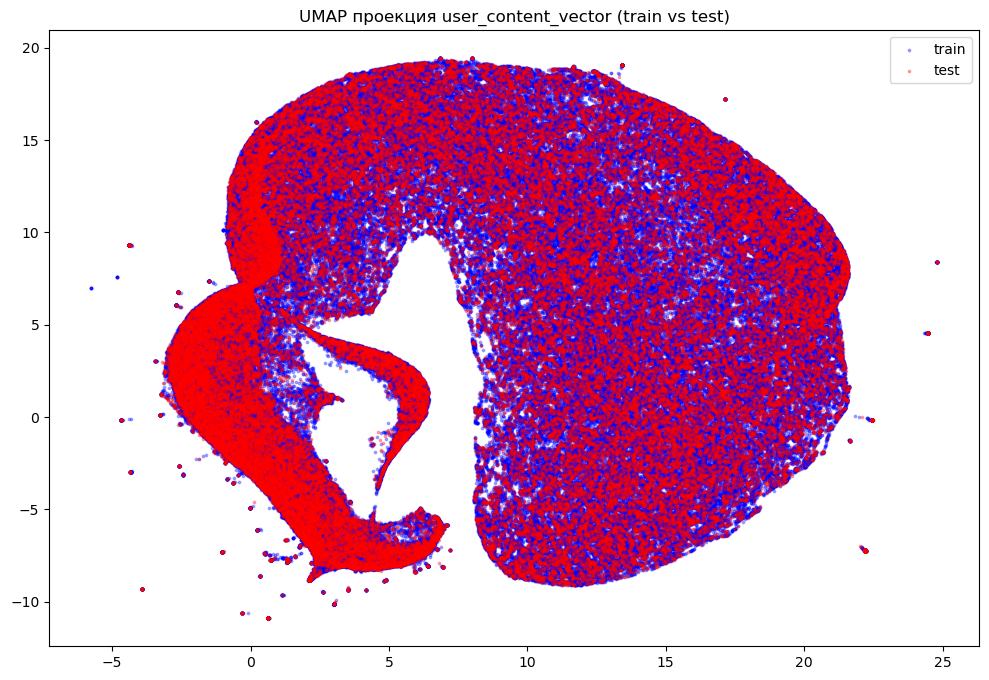

In [23]:
train_len = len(user_vectors_train)

plt.figure(figsize=(12, 8))
plt.scatter(user_vectors_2d[:train_len, 0], user_vectors_2d[:train_len, 1], 
            s=3, alpha=0.3, label="train", c='blue')
plt.scatter(user_vectors_2d[train_len:, 0], user_vectors_2d[train_len:, 1], 
            s=3, alpha=0.3, label="test", c='red')
plt.legend()
plt.title("UMAP проекция user_content_vector (train vs test)")
plt.show()

### Вывод: Данные переплетены. Можно использовать такую разбивку

### Создаем модель (KMeans) 

In [26]:
user_vectors_train = user_vectors_train.astype(np.float64)
user_vectors_test = user_vectors_test.astype(np.float64)

In [27]:
n_clusters = 150
kmeans_users = KMeans(n_clusters=n_clusters, random_state=42, n_init='auto')
kmeans_users.fit(user_vectors_train)

KMeans(n_clusters=150, random_state=42)

In [41]:
# Предсказания
train_cluster_labels = kmeans_users.predict(user_vectors_train)
test_cluster_labels = kmeans_users.predict(user_vectors_test)

# Объединяем метки
user_cluster_labels = np.concatenate([train_cluster_labels, test_cluster_labels])

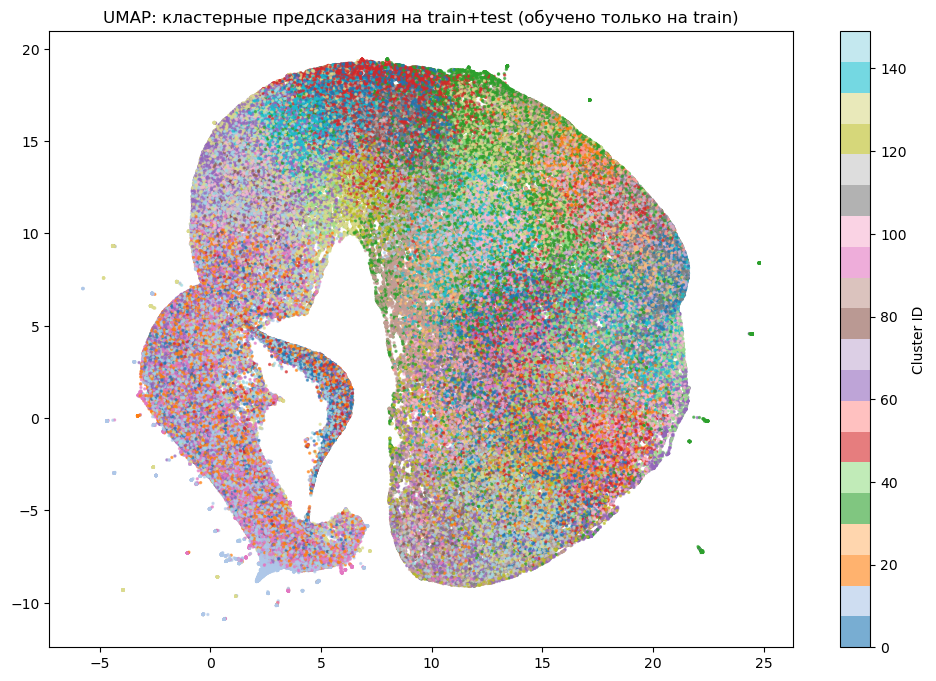

In [42]:
plt.figure(figsize=(12, 8))
scatter = plt.scatter(
    user_vectors_2d[:, 0], user_vectors_2d[:, 1],
    c=user_cluster_labels, cmap='tab20', s=2, alpha=0.6
)
plt.colorbar(scatter, label="Cluster ID")
plt.title("UMAP: кластерные предсказания на train+test (обучено только на train)")
plt.show()

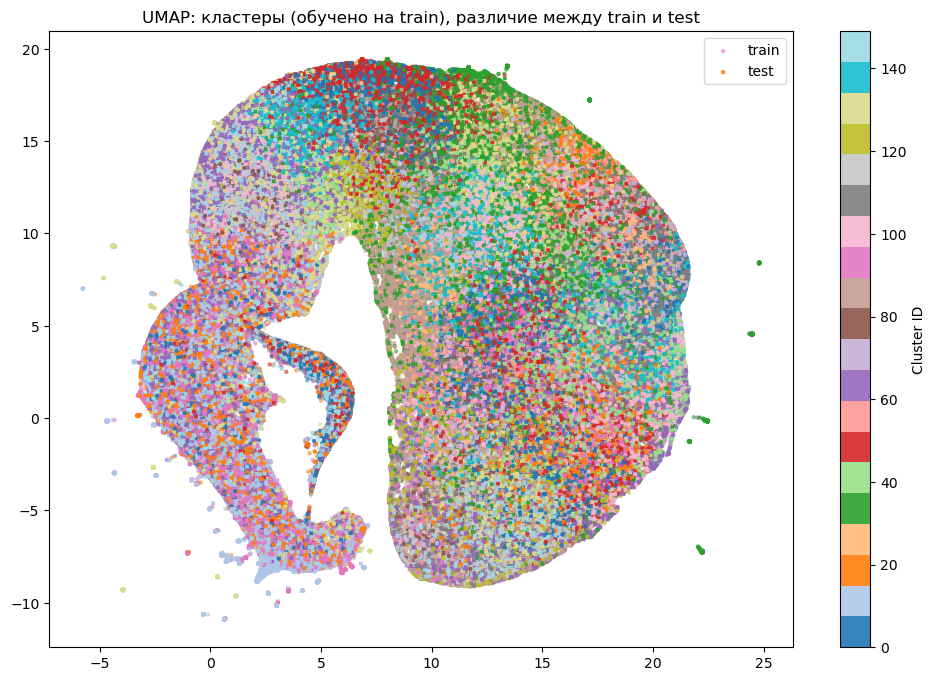

In [43]:
plt.figure(figsize=(12, 8))

# train — кружочки
plt.scatter(
    user_vectors_2d[:train_len, 0], user_vectors_2d[:train_len, 1],
    c=train_cluster_labels, cmap='tab20', s=5, alpha=0.5, marker='o', label='train'
)

# test — крестики
plt.scatter(
    user_vectors_2d[train_len:, 0], user_vectors_2d[train_len:, 1],
    c=test_cluster_labels, cmap='tab20', s=5, alpha=0.9, marker='x', label='test'
)

plt.title("UMAP: кластеры (обучено на train), различие между train и test")
plt.legend()
plt.colorbar(label="Cluster ID")
plt.show()

In [30]:
def visualize_recommendations_hybrid(base_recommendations, similar_users_recommendations, top_n=10):
    """
    Функция для визуализации сравнения рекомендательных списков.

    :param base_recommendations: Список ID фильмов или DataFrame с колонкой 'movie_id'.
    :param similar_users_recommendations: Словарь рекомендаций (user_id -> список movie_id) или DataFrame с колонками 'user_id', 'movie_id'.
    :param top_n: Количество фильмов для отображения.
    """
    import matplotlib.pyplot as plt
    import seaborn as sns
    from matplotlib_venn import venn2
    from collections import defaultdict

    # --- Подготовка данных ---

    # 1. Преобразуем base_recommendations (если это DataFrame)
    if isinstance(base_recommendations, pd.DataFrame):
        base_recommendations = base_recommendations['movie_id'].tolist()

    # 2. Преобразуем similar_users_recommendations (если это DataFrame)
    if isinstance(similar_users_recommendations, pd.DataFrame):
        similar_users_recommendations = (
            similar_users_recommendations
            .groupby('user_id')['movie_id']
            .apply(list)
            .to_dict()
        )

    first_similar = list(similar_users_recommendations.values())[0]

    fig, axs = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle("Сравнение Рекомендательных Списков", fontsize=16)

    # --- Диаграмма Венна ---
    set1 = set(base_recommendations)
    set2 = set(first_similar)
    venn2([set1, set2], set_labels=('Hybrid', 'Base'), ax=axs[0, 0])
    axs[0, 0].set_title("Диаграмма Венна")

    print("Jaccard Similarity:", jaccard_similarity(base_recommendations, first_similar))
    print("Precision@5:", precision_at_k(base_recommendations, first_similar, k=5))
    print("Intersection Count:", intersection_count(base_recommendations, first_similar))
    print("RBO Score:", rbo_score(base_recommendations, first_similar))

    # --- Barplot Пересечений ---
    intersection_counts = top_n_intersections(base_recommendations, first_similar, top_n=top_n)
    axs[0, 1].bar(range(1, len(intersection_counts) + 1), intersection_counts)
    axs[0, 1].set_title("Пересечения в Top-N")
    axs[0, 1].set_xlabel("Top-N")
    axs[0, 1].set_ylabel("Кол-во общих фильмов")

    # --- График RBO Score ---
    rbo_scores = [rbo_score(base_recommendations[:k], first_similar[:k]) for k in range(1, min(len(base_recommendations), len(first_similar)) + 1)]
    axs[1, 0].plot(range(1, len(rbo_scores)+1), rbo_scores, marker='o')
    axs[1, 0].set_title("RBO по глубине")
    axs[1, 0].set_xlabel("Глубина списка")
    axs[1, 0].set_ylabel("RBO")

    # --- Heatmap Совпадений ---
    match_matrix = build_match_matrix(base_recommendations, first_similar)
    sns.heatmap(match_matrix, cmap='Blues', cbar=False, ax=axs[1, 1],
                xticklabels=first_similar, yticklabels=base_recommendations, linewidths=0.5, linecolor='gray')
    axs[1, 1].set_title("Heatmap Совпадений по Позициям")
    axs[1, 1].set_xlabel("Base Recommend")
    axs[1, 1].set_ylabel("Hybrid Recommend")

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

In [48]:
# def get_user_recommendations_with_ensemble(user_id, user_content_vector, user_encoder, ratings_csr, kmeans_users, importance_df, movies_df, item_encoder, top_n=50, num_user=5):
#     user_idx = user_encoder.transform([user_id])[0]
#     user_vector = user_content_vector[user_idx]

#     # Шаг 1: кластер и ближайшие пользователи
#     user_cluster = kmeans_users.predict([user_vector])[0]
#     cluster_users_idx = np.where(kmeans_users.labels_ == user_cluster)[0]

#     # Удаляем себя и идентичных (по вектору)
#     distances = cosine_similarity(user_vector.reshape(1, -1), user_content_vector[cluster_users_idx])
#     distances = distances.flatten()

#     # Создаем список индексов похожих пользователей, удаляя себя и "слишком похожих"
#     filtered_users = []
#     for lower in np.arange(0.1, 0.99, 0.1):
#         upper = lower + 0.1
#         for idx, dist in zip(cluster_users_idx, distances):
#             if idx != user_idx and lower < dist <= upper:
#                 filtered_users.append((idx, dist))
#                 if len(filtered_users) >= num_user:
#                     break
#         if len(filtered_users) >= num_user:
#             break
    
#     # Проверка: если не нашли — предупредим
#     if not filtered_users:
#         print(f"⚠️ Нет подходящих пользователей для user_id={user_id} в диапазоне dist ∈ (0.1, 0.99)")
#     else:
#         print(f"✅ Найдено {len(filtered_users)} похожих пользователей")
    
#     # 2. Сортировка по убыванию близости
#     filtered_users = sorted(filtered_users, key=lambda x: -x[1])[:num_user]

#     recommendation_scores = defaultdict(lambda: {"score": 0, "users": set()})
#     similar_users_recommendations = {}

#     # Шаг 2: собираем рекомендации от похожих юзеров
#     for rank, (sim_user_idx, sim_score) in enumerate(filtered_users):
#         sim_user_id = user_encoder.inverse_transform([sim_user_idx])[0]
#         recommended_items = get_recommendations(sim_user_idx, ratings_csr, top_n=100)

#         user_rec_list = []

#         for movie_id in recommended_items:
#             if movie_id in item_encoder.classes_:
#                 movie_row = movies_df[movies_df['movieId'] == movie_id]
#                 if movie_row.empty:
#                     continue

#                 title = movie_row['title'].values[0]
#                 genres = movie_row['genres'].values[0]

#                 recommendation_scores[movie_id]["score"] += 1
#                 recommendation_scores[movie_id]["users"].add(sim_user_id)

#                 user_rec_list.append({
#                     'user_id': sim_user_id,
#                     'movie_id': movie_id,
#                     'title': title,
#                     'genres': genres,
#                     'similarity_rank': rank + 1
#                 })

#         similar_users_recommendations[sim_user_id] = user_rec_list

#     # Итоговая таблица с рейтингом по повторяемости
#     final_recs = []
#     for movie_id, data in recommendation_scores.items():
#         movie_row = movies_df[movies_df['movieId'] == movie_id]
#         if movie_row.empty:
#             continue

#         title = movie_row['title'].values[0]
#         genres = movie_row['genres'].values[0]

#         final_recs.append({
#             'movie_id': movie_id,
#             'title': title,
#             'genres': genres,
#             'ensemble_score': data['score'],
#             'supported_by_users': list(data['users'])
#         })

#     final_df = pd.DataFrame(final_recs).sort_values(by='ensemble_score', ascending=False).head(top_n)

#     # Объединённые рекомендации от всех похожих юзеров
#     similar_users_recommendations_df = pd.DataFrame([
#         rec for recs in similar_users_recommendations.values() for rec in recs
#     ])

#     return final_df, similar_users_recommendations_df

def get_user_recommendations_with_ensemble(
    user_id, user_content_vector, user_encoder,
    ratings_csr, kmeans_users, importance_df,
    movies_df, item_encoder, top_n=50, num_user=5,
    is_test=False
):
    # Внимание: user_idx должен соответствовать user_content_vector
    try:
        user_idx = user_encoder.transform([user_id])[0]
        user_vector = user_content_vector[user_idx]
    except IndexError:
        raise ValueError(f"User ID {user_id} не найден в переданном user_encoder")

    user_cluster = kmeans_users.predict([user_vector])[0]
    cluster_users_idx = np.where(kmeans_users.labels_ == user_cluster)[0]

    # Для test-пользователя — мы ищем ближайших в тренировочных векторах!
    cluster_user_vectors = (
        user_content_vector[cluster_users_idx] if not is_test
        else user_vectors_train[cluster_users_idx]
    )

    distances = cosine_similarity(user_vector.reshape(1, -1), cluster_user_vectors).flatten()

    # Подбор похожих пользователей (из train)
    filtered_users = []
    for lower in np.arange(0.1, 0.99, 0.1):
        upper = lower + 0.1
        for idx, dist in zip(cluster_users_idx, distances):
            if (not is_test and idx != user_idx) or is_test:
                if lower < dist <= upper:
                    filtered_users.append((idx, dist))
                    if len(filtered_users) >= num_user:
                        break
        if len(filtered_users) >= num_user:
            break

    if not filtered_users:
        print(f"⚠️ Нет подходящих пользователей для user_id={user_id} в диапазоне dist ∈ (0.1, 0.99)")
    else:
        print(f"✅ Найдено {len(filtered_users)} похожих пользователей")

    filtered_users = sorted(filtered_users, key=lambda x: -x[1])[:num_user]

    recommendation_scores = defaultdict(lambda: {"score": 0, "users": set()})
    similar_users_recommendations = {}

    for rank, (sim_user_idx, sim_score) in enumerate(filtered_users):
        sim_user_id = user_encoder.inverse_transform([sim_user_idx])[0]
        recommended_items = get_recommendations(sim_user_idx, ratings_csr, top_n=100)

        user_rec_list = []
        for movie_id in recommended_items:
            if movie_id in item_encoder.classes_:
                movie_row = movies_df[movies_df['movieId'] == movie_id]
                if movie_row.empty:
                    continue
                title = movie_row['title'].values[0]
                genres = movie_row['genres'].values[0]

                recommendation_scores[movie_id]["score"] += 1
                recommendation_scores[movie_id]["users"].add(sim_user_id)

                user_rec_list.append({
                    'user_id': sim_user_id,
                    'movie_id': movie_id,
                    'title': title,
                    'genres': genres,
                    'similarity_rank': rank + 1
                })

        similar_users_recommendations[sim_user_id] = user_rec_list

    final_recs = []
    for movie_id, data in recommendation_scores.items():
        movie_row = movies_df[movies_df['movieId'] == movie_id]
        if movie_row.empty:
            continue
        title = movie_row['title'].values[0]
        genres = movie_row['genres'].values[0]
        final_recs.append({
            'movie_id': movie_id,
            'title': title,
            'genres': genres,
            'ensemble_score': data['score'],
            'supported_by_users': list(data['users'])
        })

    final_df = pd.DataFrame(final_recs).sort_values(by='ensemble_score', ascending=False).head(top_n)

    similar_users_recommendations_df = pd.DataFrame([
        rec for recs in similar_users_recommendations.values() for rec in recs
    ])

    return final_df, similar_users_recommendations_df

# Функция для получения рекомендаций для конкретного пользователя
def get_recommendations(user_idx, ratings_csr, top_n=5):
    """
    Получает топ-N рекомендаций для пользователя на основе разреженной матрицы взаимодействий.
    
    :param user_idx: Индекс пользователя.
    :param ratings_csr: Разреженная матрица взаимодействий.
    :param top_n: Количество рекомендованных фильмов.
    :return: Список рекомендованных фильмов.
    """
   # Получаем оценки текущего пользователя
    user_ratings = ratings_csr[user_idx].toarray().flatten()  # Рейтинг пользователя
    unrated_movies = np.where(user_ratings == 0)[0]  # Фильмы, которые не оценены
    
    # Оцениваем все фильмы, которые пользователь не оценивал, на основе сходства
    # Работаем с разреженными матрицами
    scores = ratings_csr[unrated_movies].dot(ratings_csr[user_idx].T).toarray().flatten()
    
    # Получаем индексы рекомендованных фильмов
    recommended_movies_idx = unrated_movies[np.argsort(scores)[-top_n:]]
    
    return recommended_movies_idx

## 14. Оффлайн тестирование

### На train

In [57]:
user_id = 1

final_df_train, similar_users_recommendations_train = get_user_recommendations_with_ensemble(
    user_id=user_id,
    user_content_vector=user_vectors_train,  # ← трендовая модель
    user_encoder=user_encoder,
    ratings_csr=ratings_csr,                         # ← только train
    kmeans_users=kmeans_users,
    importance_df=importance_df,
    movies_df=movies,
    item_encoder=item_encoder,
    top_n=50,
    num_user=5,
    is_test=False
)


✅ Найдено 5 похожих пользователей


In [58]:
final_df_train

,movie_id,title,genres,ensemble_score,supported_by_users
15,83227,L.627 (1992),Crime|Drama|Thriller,5,"[258250, 47886, 38385, 45973, 40985]"
23,5992,"Hours, The (2002)",Drama|Romance,2,"[40985, 47886]"
45,4879,High Heels and Low Lifes (2001),Action|Comedy|Crime|Drama,2,"[38385, 47886]"
44,6385,Whale Rider (2002),Drama,2,"[38385, 258250]"
43,3022,"General, The (1926)",Comedy|War,2,"[38385, 258250]"
51,2401,Pale Rider (1985),Western,2,"[38385, 47886]"
56,43624,Here Comes the Groom (1951),Comedy|Musical|Romance,2,"[38385, 258250]"
34,56274,Margot at the Wedding (2007),Drama,2,"[40985, 47886]"
57,31682,"Nomi Song, The (2004)",Documentary|Musical,2,"[38385, 258250]"
32,2843,"Black Cat, White Cat (Crna macka, beli macor) ...",Comedy|Romance,2,"[40985, 38385]"


### НА Test

In [45]:
def find_top_similar_users(user_id, user_vectors_train, user_vectors_test, user_encoder, top_k=10):
    """
    Находит топ-N похожих пользователей из теста по user_id из трейна.
    
    :param user_id: ID пользователя из трейна
    :param user_vectors_train: Векторы пользователей из трейна
    :param user_vectors_test: Векторы пользователей из теста
    :param user_encoder: Encoder, общий для train и test
    :param top_k: Сколько похожих пользователей из теста вернуть
    :return: DataFrame с топ-N наиболее похожими пользователями
    """
    user_idx_train = user_encoder.transform([user_id])[0]
    user_vector_train = user_vectors_train[user_idx_train].reshape(1, -1)
    
    similarities = cosine_similarity(user_vector_train, user_vectors_test).flatten()
    top_indices = np.argsort(similarities)[-top_k:][::-1]
    
    top_user_ids = user_encoder.inverse_transform(top_indices)
    top_scores = similarities[top_indices]
    
    def categorize_similarity(score):
        if score == 1.0:
            return "🔁 идентичный"
        elif score > 0.99:
            return "✅ почти идентичный"
        elif score > 0.95:
            return "👍 близкий"
        elif score > 0.90:
            return "👌 средний"
        else:
            return "❔ слабый"
    
    data = {
        "train_user_id": [user_id] * top_k,
        "test_user_id": top_user_ids,
        "similarity": top_scores,
        "similarity_level": [categorize_similarity(s) for s in top_scores]
    }

    return pd.DataFrame(data)

In [46]:
similar_users_df = find_top_similar_users(
    user_id=1,
    user_vectors_train=user_vectors_train,
    user_vectors_test=user_vectors_test,
    user_encoder=user_encoder,
    top_k=10
)

similar_users_df

,train_user_id,test_user_id,similarity,similarity_level
0,1,41091,0.999959,✅ почти идентичный
1,1,59103,0.999938,✅ почти идентичный
2,1,20843,0.999938,✅ почти идентичный
3,1,48960,0.999937,✅ почти идентичный
4,1,2358,0.999935,✅ почти идентичный
5,1,3711,0.999932,✅ почти идентичный
6,1,2554,0.999932,✅ почти идентичный
7,1,62768,0.999931,✅ почти идентичный
8,1,57988,0.999931,✅ почти идентичный
9,1,37750,0.999927,✅ почти идентичный


In [50]:
user_id = 41091

final_df_test, recs_test = get_user_recommendations_with_ensemble(
    user_id=user_id,
    user_content_vector=user_vectors_test,
    user_encoder=user_encoder,
    ratings_csr=ratings_csr, 
    kmeans_users=kmeans_users,
    importance_df=importance_df,
    movies_df=movies,
    item_encoder=item_encoder,
    top_n=50,
    num_user=5,
    is_test=True
)

✅ Найдено 5 похожих пользователей


In [51]:
final_df_test

,movie_id,title,genres,ensemble_score,supported_by_users
26,63810,When Willie Comes Marching Home (1950),Comedy|War,3,"[32, 21, 146047]"
14,83227,L.627 (1992),Crime|Drama|Thriller,3,"[2, 21, 146047]"
47,6777,Judgment at Nuremberg (1961),Drama,2,"[32, 17]"
27,54999,Shoot 'Em Up (2007),Action|Comedy|Crime,2,"[21, 146047]"
23,80659,"Edward, My Son (1949)",Drama,2,"[17, 21]"
28,2843,"Black Cat, White Cat (Crna macka, beli macor) ...",Comedy|Romance,2,"[21, 146047]"
29,26307,Five Fingers of Death (1972),Action|Drama|Romance,2,"[17, 21]"
20,4694,Left Luggage (1998),Drama,2,"[2, 146047]"
32,2401,Pale Rider (1985),Western,2,"[17, 21]"
33,3022,"General, The (1926)",Comedy|War,2,"[21, 146047]"


Jaccard Similarity: 0.20481927710843373
Precision@5: 0.2
Intersection Count: 17
RBO Score: 0.29964094447466505


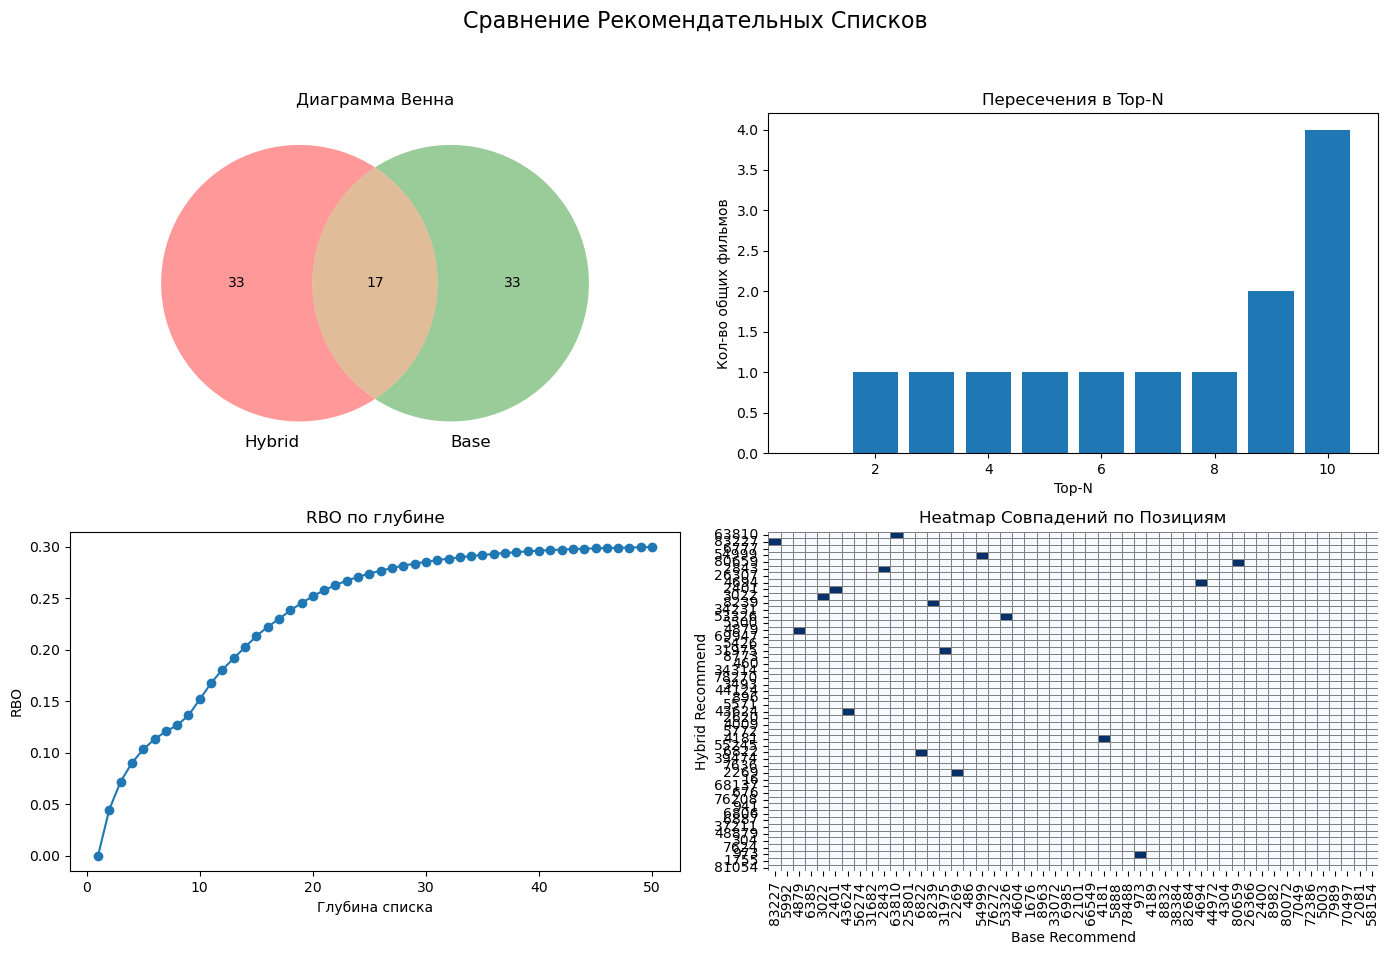

In [59]:
visualize_recommendations_df(final_df_test, final_df_train)

### Выводы:
- Пользователи с почти идентичными векторами имеют пересечение рекомендаций, но не полное, что 👌 логично — в ансамбле участвуют разные соседи, немного отличающиеся.
- RBO ~0.3 говорит, что списки всё-таки довольно разные по ранжированию, несмотря на пересечения.
- Precision@5 = 0.2 — хороший сигнал с учетом что это рекомендации от других пользователей.

In [60]:
user_id = 59103

final_df_test2, recs_test2 = get_user_recommendations_with_ensemble(
    user_id=user_id,
    user_content_vector=user_vectors_test,
    user_encoder=user_encoder,
    ratings_csr=ratings_csr, 
    kmeans_users=kmeans_users,
    importance_df=importance_df,
    movies_df=movies,
    item_encoder=item_encoder,
    top_n=50,
    num_user=5,
    is_test=True
)

✅ Найдено 5 похожих пользователей


In [61]:
final_df_test2

,movie_id,title,genres,ensemble_score,supported_by_users
22,31975,Tombs of the Blind Dead (La noche del terror c...,Horror|Mystery,3,"[48334, 113734, 84543]"
44,2843,"Black Cat, White Cat (Crna macka, beli macor) ...",Comedy|Romance,3,"[48334, 113734, 84543]"
40,4694,Left Luggage (1998),Drama,2,"[113734, 119351]"
21,71760,India Song (1975),Drama|Fantasy|Romance,2,"[113734, 84543]"
19,72386,Broken Embraces (Los abrazos rotos) (2009),Drama|Romance|Thriller,2,"[113734, 84543]"
67,4879,High Heels and Low Lifes (2001),Action|Comedy|Crime|Drama,2,"[84543, 119351]"
36,68067,Escape from Fort Bravo (1953),Western,2,"[48334, 113734]"
28,79515,Farsan (2010),Comedy,2,"[113734, 84543]"
38,53326,Them (Ils) (2006),Horror,2,"[48334, 113734]"
62,83227,L.627 (1992),Crime|Drama|Thriller,2,"[48334, 119351]"


Jaccard Similarity: 0.25
Precision@5: 0.0
Intersection Count: 20
RBO Score: 0.17295763717380594


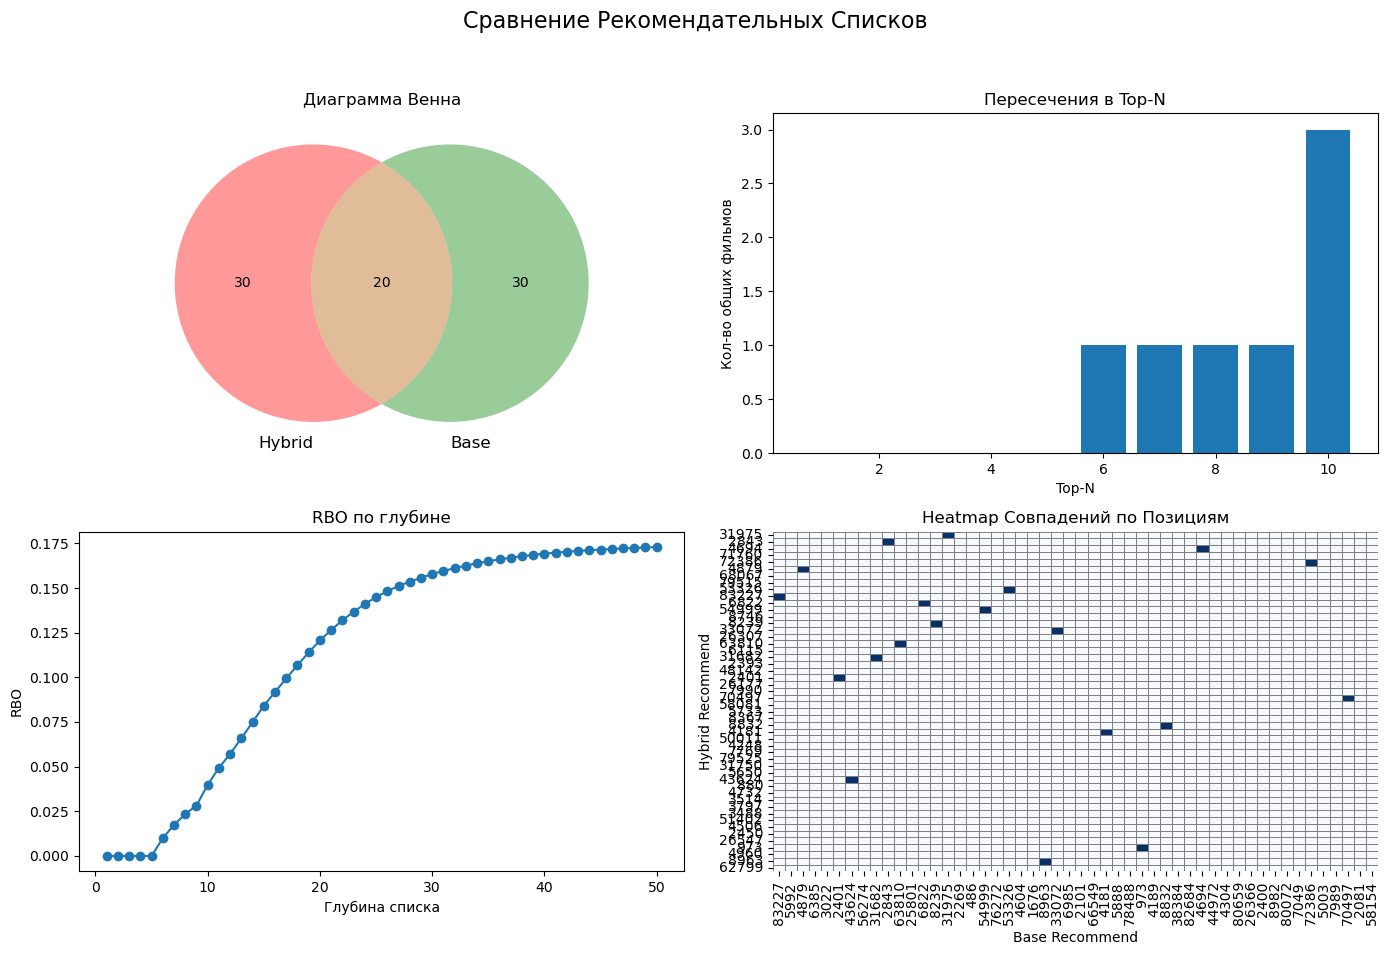

In [62]:
visualize_recommendations_df(final_df_test2, final_df_train)

In [65]:
def visualize_recommendations(final_df, similar_users_recommendations_df, new_final_df=None, top_n=10):
    """
    Визуализация сравнений между рекомендациями основного пользователя и каждого из похожих,
    а также между двумя наборами рекомендаций (если передан new_final_df).

    :param final_df: DataFrame с колонкой 'movie_id' — базовые рекомендации.
    :param similar_users_recommendations_df: DataFrame с колонками ['user_id', 'movie_id', 'similarity_rank'] — рекомендации от похожих пользователей.
    :param new_final_df: (Optional) DataFrame с новым набором рекомендаций для сравнения.
    :param top_n: Сколько фильмов учитывать в сравнении.
    """
    base_recommendations = final_df['movie_id'].tolist()[:top_n]

    if new_final_df is not None:
        new_recommendations = new_final_df['movie_id'].tolist()[:top_n]
    
    similar_user_ids = similar_users_recommendations_df['user_id'].unique()

    for sim_user_id in similar_user_ids:
        sim_user_recs = similar_users_recommendations_df[similar_users_recommendations_df['user_id'] == sim_user_id]
        sim_recommendations = sim_user_recs.sort_values('similarity_rank')['movie_id'].tolist()[:top_n]

        print(f"\nСравнение с пользователем {sim_user_id}")
        fig, axs = plt.subplots(2, 2, figsize=(14, 10))
        fig.suptitle(f"Сравнение с пользователем {sim_user_id}", fontsize=16)

        # --- Диаграмма Венна для базовых рекомендаций и новых ---
        set1 = set(base_recommendations)
        set2 = set(sim_recommendations)
        venn2([set1, set2], set_labels=('Base', f'User {sim_user_id}'), ax=axs[0, 0])
        axs[0, 0].set_title("Диаграмма Венна")

        # Метрики
        print("Jaccard Similarity:", jaccard_similarity(base_recommendations, sim_recommendations))
        print("Precision@5:", precision_at_k(base_recommendations, sim_recommendations, k=5))
        print("Intersection Count:", intersection_count(base_recommendations, sim_recommendations))
        print("RBO Score:", rbo_score(base_recommendations, sim_recommendations))

        # --- Barplot Пересечений ---
        intersection_counts = top_n_intersections(base_recommendations, sim_recommendations, top_n=top_n)
        axs[0, 1].bar(range(1, len(intersection_counts) + 1), intersection_counts)
        axs[0, 1].set_title("Пересечения в Top-N")
        axs[0, 1].set_xlabel("Top-N")
        axs[0, 1].set_ylabel("Кол-во общих фильмов")

        # --- RBO по глубине ---
        rbo_scores = [rbo_score(base_recommendations[:k], sim_recommendations[:k]) for k in range(1, min(len(base_recommendations), len(sim_recommendations)) + 1)]
        axs[1, 0].plot(range(1, len(rbo_scores)+1), rbo_scores, marker='o')
        axs[1, 0].set_title("RBO по глубине")
        axs[1, 0].set_xlabel("Глубина списка")
        axs[1, 0].set_ylabel("RBO")

        # --- Heatmap Совпадений (если есть новые рекомендации) ---
        if new_final_df is not None:
            set2_new = set(new_recommendations)
            match_matrix = build_match_matrix(base_recommendations, new_recommendations)
            sns.heatmap(match_matrix, cmap='Blues', cbar=False, ax=axs[1, 1],
                        xticklabels=new_recommendations, yticklabels=base_recommendations,
                        linewidths=0.5, linecolor='gray')
            axs[1, 1].set_title("Heatmap Совпадений: Base vs New Recommendations")
            axs[1, 1].set_xlabel("New Recommendations")
            axs[1, 1].set_ylabel("Base Recommendations")
        else:
            match_matrix = build_match_matrix(base_recommendations, sim_recommendations)
            sns.heatmap(match_matrix, cmap='Blues', cbar=False, ax=axs[1, 1],
                        xticklabels=sim_recommendations, yticklabels=base_recommendations,
                        linewidths=0.5, linecolor='gray')
            axs[1, 1].set_title("Heatmap Совпадений по Позициям")
            axs[1, 1].set_xlabel("User Recommendations")
            axs[1, 1].set_ylabel("Base Recommendations")

        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        plt.show()

### Сравниваем результаты рекомендации нашего пользовтеля с ближайшими


Сравнение с пользователем 45973
Jaccard Similarity: 0.14705882352941177
Precision@5: 0.2
Intersection Count: 5
RBO Score: 0.0


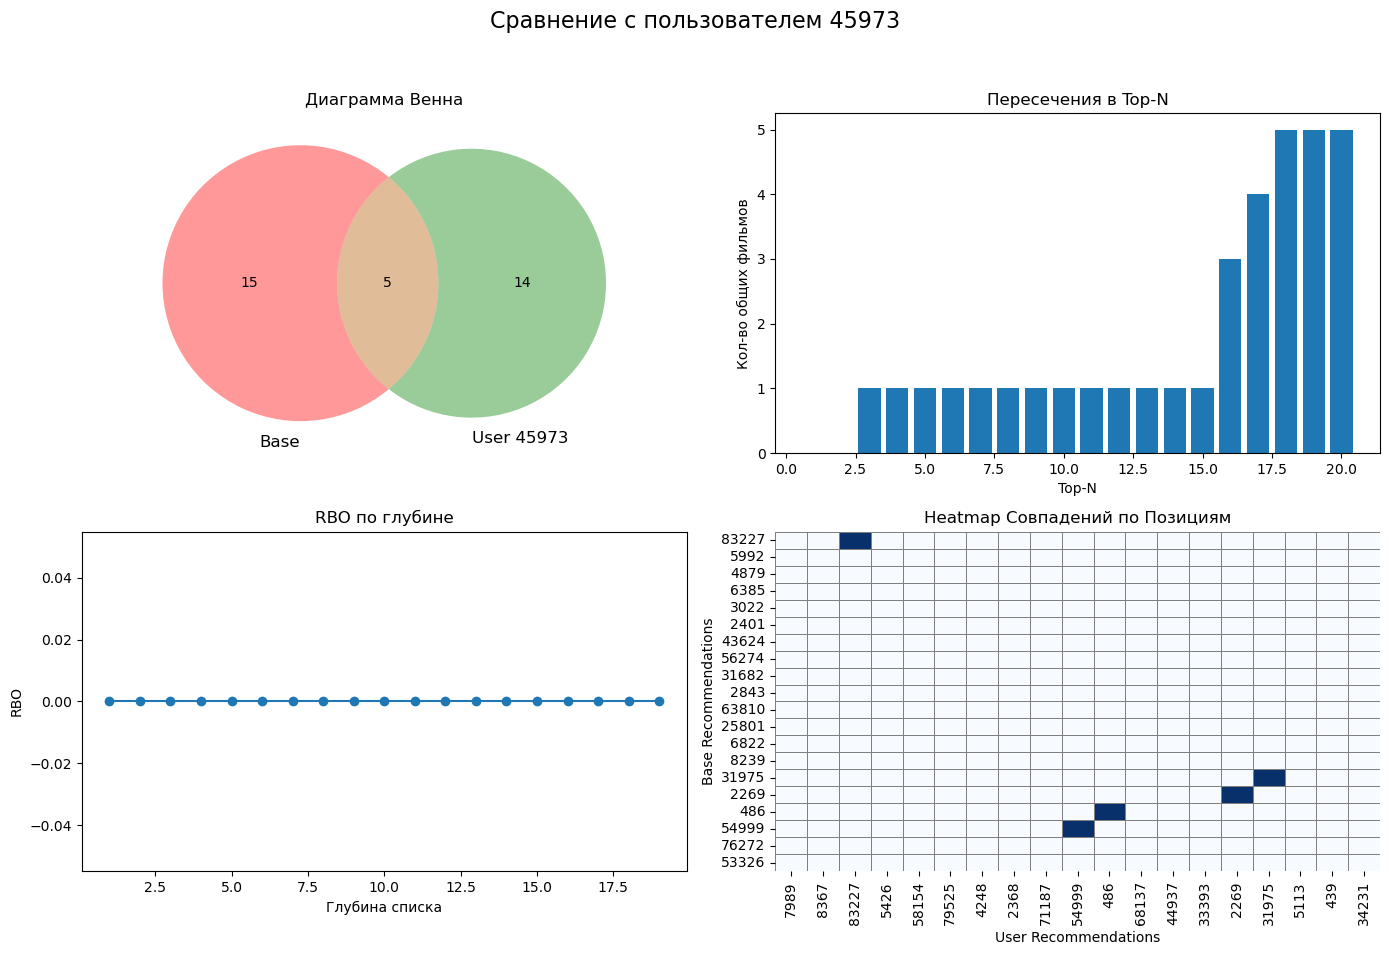


Сравнение с пользователем 40985
Jaccard Similarity: 0.14285714285714285
Precision@5: 0.0
Intersection Count: 5
RBO Score: 0.3874204890000001


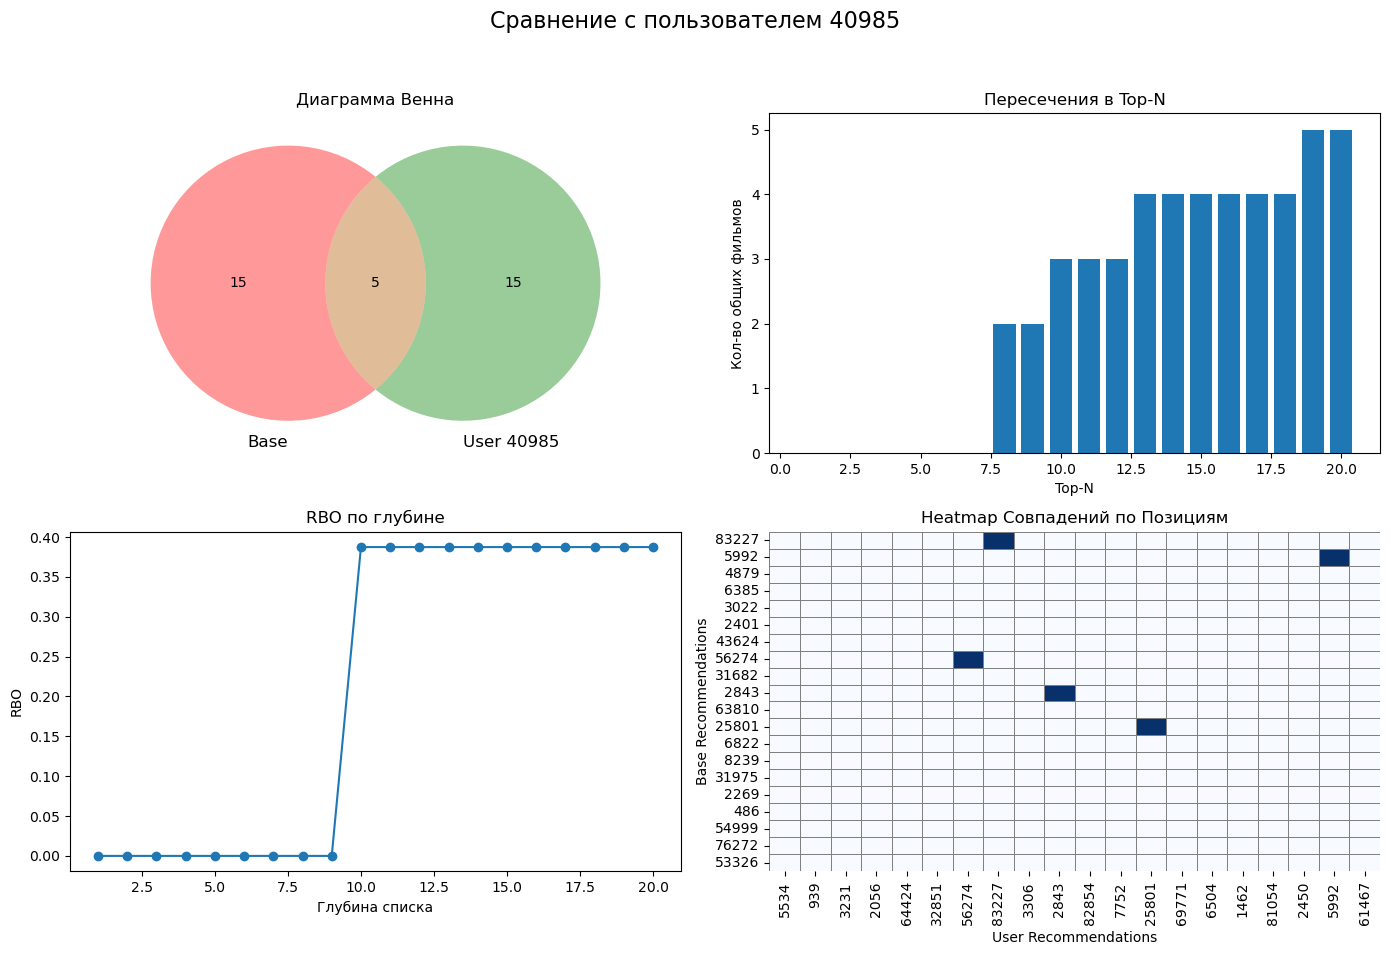


Сравнение с пользователем 38385
Jaccard Similarity: 0.3333333333333333
Precision@5: 0.0
Intersection Count: 10
RBO Score: 0.2541865828329001


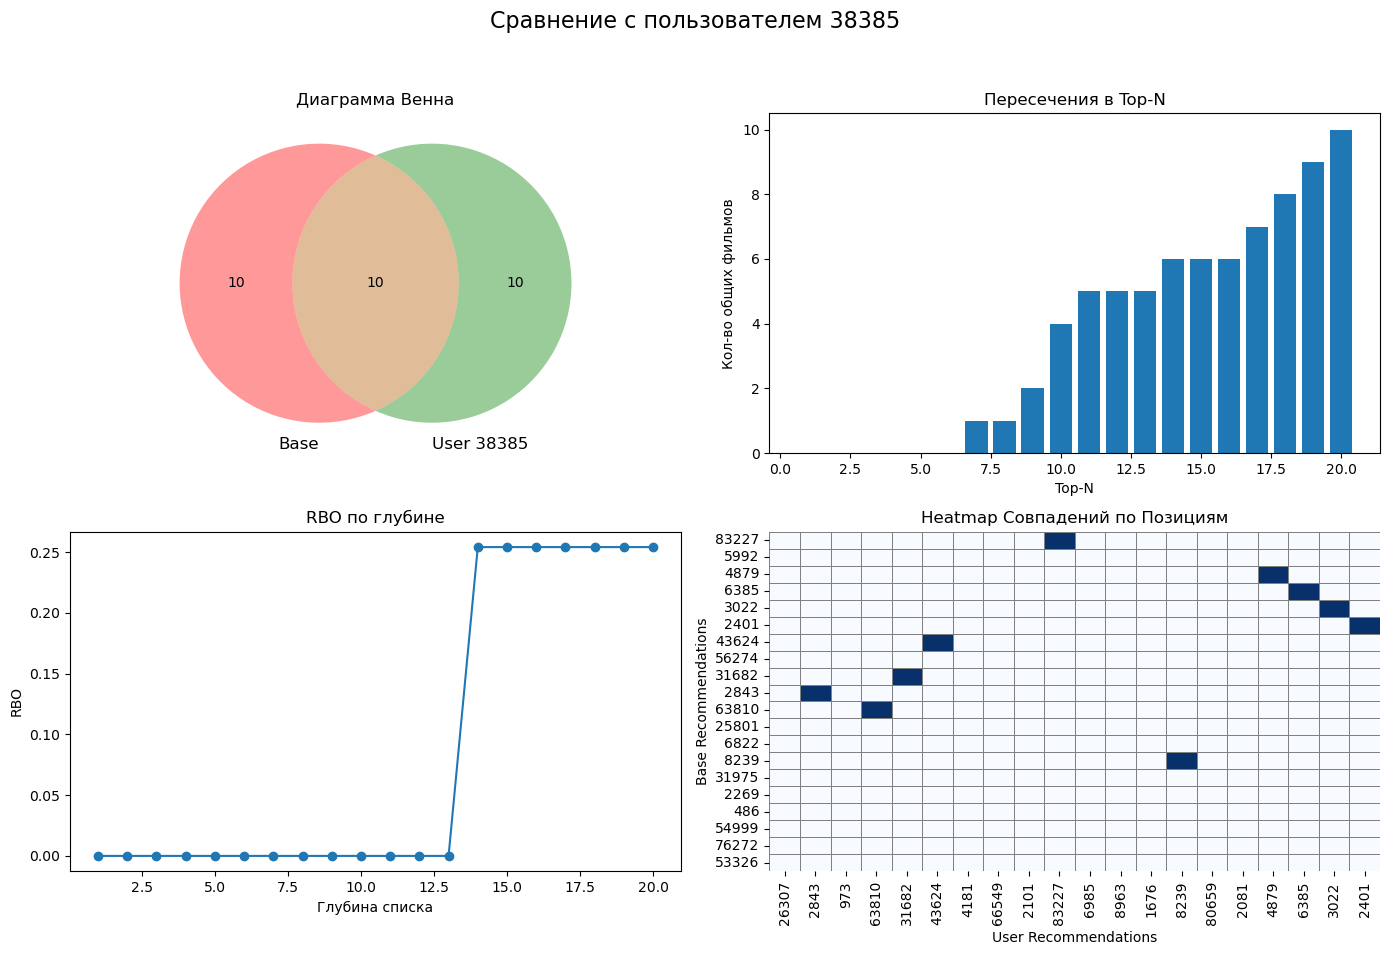


Сравнение с пользователем 47886
Jaccard Similarity: 0.26666666666666666
Precision@5: 0.0
Intersection Count: 8
RBO Score: 0.5904900000000001


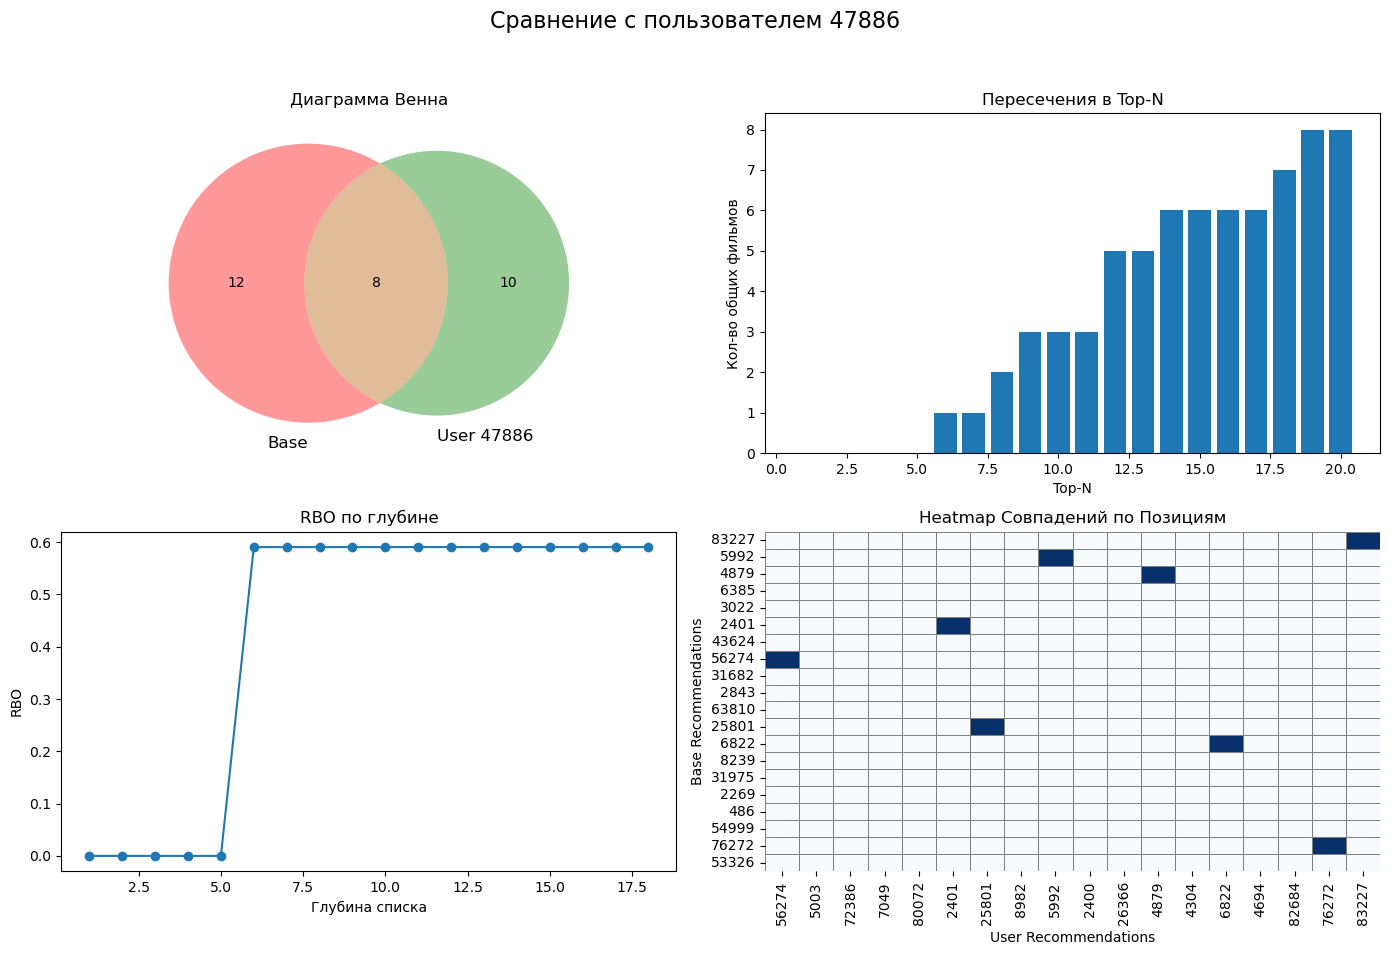


Сравнение с пользователем 258250
Jaccard Similarity: 0.42857142857142855
Precision@5: 0.2
Intersection Count: 12
RBO Score: 0.18530201888518416


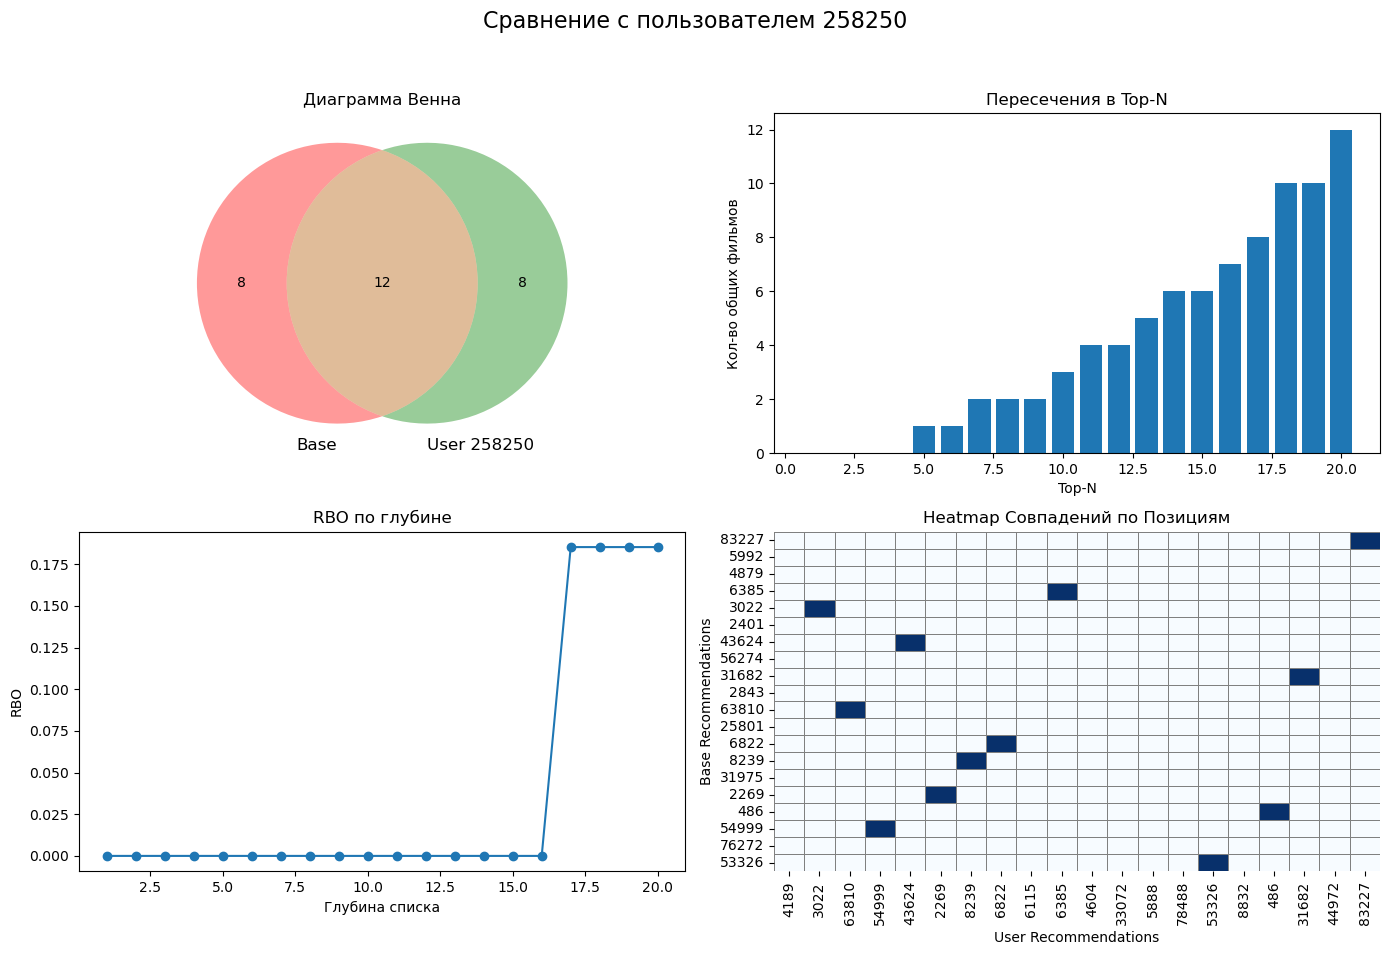

In [66]:
visualize_recommendations(final_df_train, similar_users_recommendations_train, top_n=20)

## 11.Создаем функцию динамического добавления пользователя: 

### Вначале сделаем отдельную кластеризацию для общего вектора

In [67]:
n_clusters = 150
kmeans_users_full = KMeans(n_clusters=n_clusters, random_state=42, n_init='auto')
kmeans_users_full.fit(user_content_vector)

KMeans(n_clusters=150, random_state=42)

In [68]:
def create_synthetic_user_from_existing(base_user_id, ratings, user_encoder, noise_level=0.1):
    """
    Создаёт синтетического пользователя на основе существующего, добавляя шум к его рейтингам.
    Возвращает словарь movie_id -> noisy_rating
    """
    base_user_idx = user_encoder.transform([base_user_id])[0]
    base_ratings = ratings[ratings['user_idx'] == base_user_idx]

    new_user_ratings = {}
    for _, row in base_ratings.iterrows():
        movie_id = row['movieId']
        noisy_rating = min(max(row['rating'] + np.random.normal(0, noise_level), 0.5), 5.0)
        new_user_ratings[movie_id] = noisy_rating

    return new_user_ratings



In [69]:
# функция добавления пользователя
def add_new_user_to_system(user_ratings_dict, item_encoder, model, user_content_vector, device):
    """
    Добавляет нового пользователя по его рейтингам (movie_id -> rating).
    Прогоняет через автоэнкодер, добавляет в user_content_vector.
    Возвращает обновлённый user_content_vector и индекс нового пользователя.
    """
    # Создание разреженного вектора
    num_items = len(item_encoder.classes_)
    new_user_vector = np.zeros(num_items)

    for movie_id, rating in user_ratings_dict.items():
        if movie_id in item_encoder.classes_:
            item_idx = item_encoder.transform([movie_id])[0]
            new_user_vector[item_idx] = rating

    # Преобразуем в torch-тензор и прогоняем через encoder
    model.eval()
    with torch.no_grad():
        input_tensor = torch.tensor(new_user_vector, dtype=torch.float32).to(device)
        encoded_vector = model.encoder(input_tensor).cpu().numpy()

    # Добавим к user_content_vector
    updated_user_content_vector = np.vstack([user_content_vector, encoded_vector])
    new_user_idx = updated_user_content_vector.shape[0] - 1

    return updated_user_content_vector, new_user_idx

In [70]:
new_user_ratings = create_synthetic_user_from_existing(
    base_user_id=1,  # ← здесь ID существующего пользователя, по которому генерим нового
    ratings=ratings,
    user_encoder=user_encoder,
    noise_level=0.1  # уровень шума
)

In [71]:
updated_user_content_vector, new_user_idx = add_new_user_to_system(
    user_ratings_dict=new_user_ratings,
    item_encoder=item_encoder,
    model=model,
    user_content_vector=user_content_vector,
    device=device
)

### Пример рекомендаций уже для новгого/свежего пользователя

In [72]:
final_after_df, similar_users_recommendations_after_df = get_user_recommendations_with_ensemble(
    user_id=new_user_idx,  # уже индекс в user_content_vector
    user_content_vector=updated_user_content_vector,
    user_encoder=user_encoder,
    ratings_csr=ratings_csr,
    kmeans_users=kmeans_users_full,
    importance_df=importance_df,
    movies_df=movies,
    item_encoder=item_encoder,
    top_n=15,
    num_user=5
)

✅ Найдено 5 похожих пользователей


In [73]:
final_after_df

,movie_id,title,genres,ensemble_score,supported_by_users
37,34231,Fighter in the Wind (2004),Action|Drama,3,"[733, 1523, 1157]"
33,8773,Sherlock Holmes and the Secret Weapon (1942),Crime|Mystery|Thriller,3,"[733, 1523, 1157]"
28,80659,"Edward, My Son (1949)",Drama,3,"[733, 1523, 1157]"
22,6333,X2: X-Men United (2003),Action|Adventure|Sci-Fi|Thriller,3,"[733, 1523, 1157]"
34,4126,Less Than Zero (1987),Drama,3,"[733, 1523, 1157]"
17,63810,When Willie Comes Marching Home (1950),Comedy|War,3,"[762, 845, 1157]"
36,69947,Game of Death II (a.k.a. Tower of Death) (Si w...,Action|Mystery,3,"[733, 1523, 1157]"
31,68137,Nana (2005),Drama,2,"[733, 1157]"
27,4960,"Independent, The (2000)",Comedy,2,"[733, 1157]"
26,6385,Whale Rider (2002),Drama,2,"[733, 1157]"


### Сравним рекомендации пользователя с его ближайшими походими пользователями


Сравнение с пользователем 845
Jaccard Similarity: 0.05263157894736842
Precision@5: 0.0
Intersection Count: 1
RBO Score: 0.0


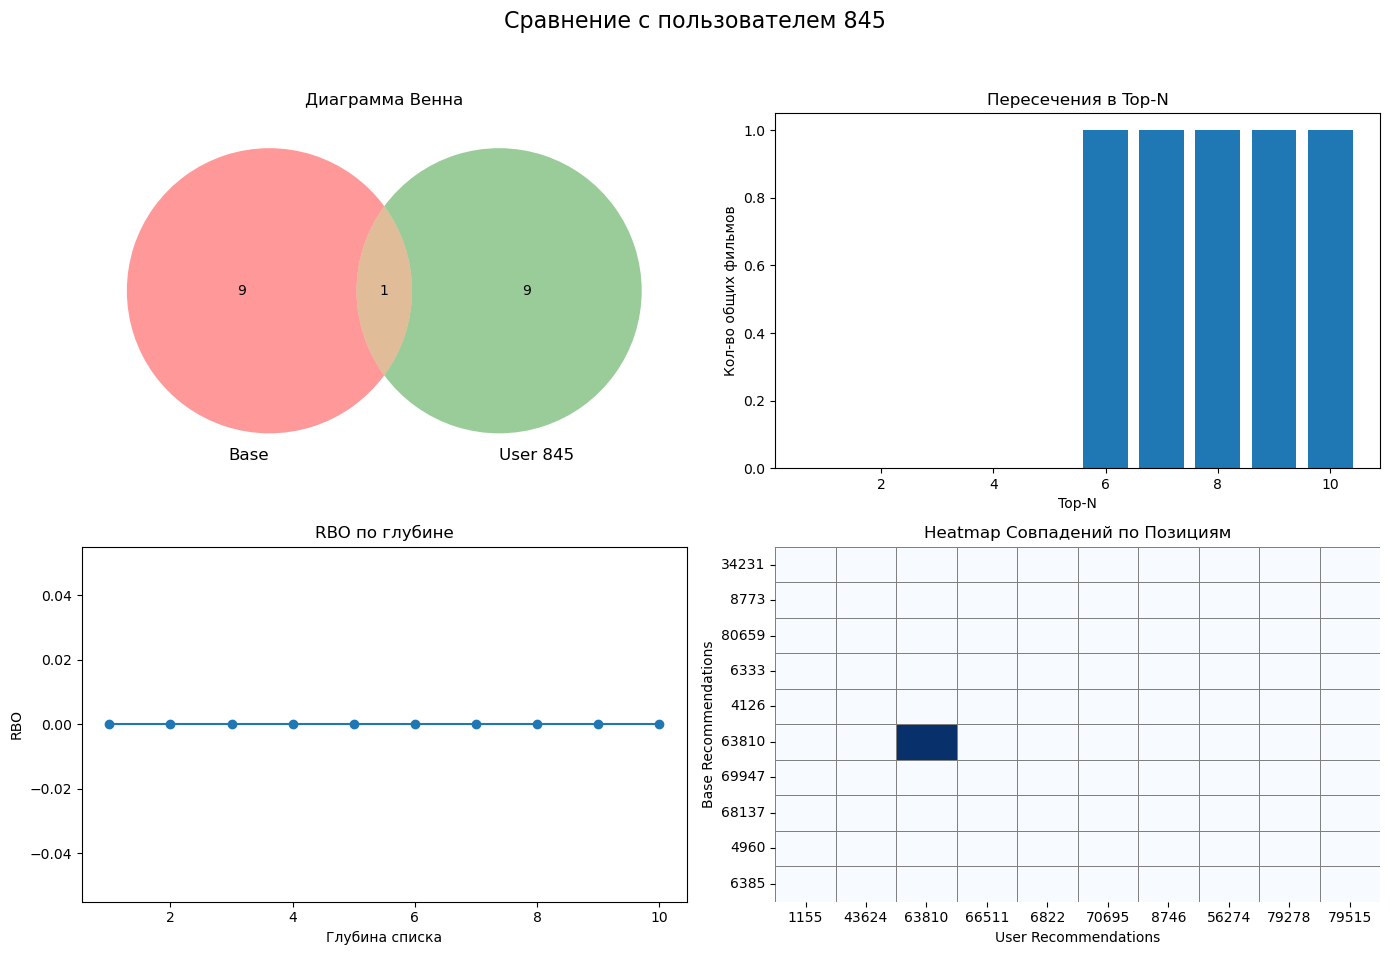


Сравнение с пользователем 1157
Jaccard Similarity: 0.42857142857142855
Precision@5: 0.4
Intersection Count: 6
RBO Score: 0.0


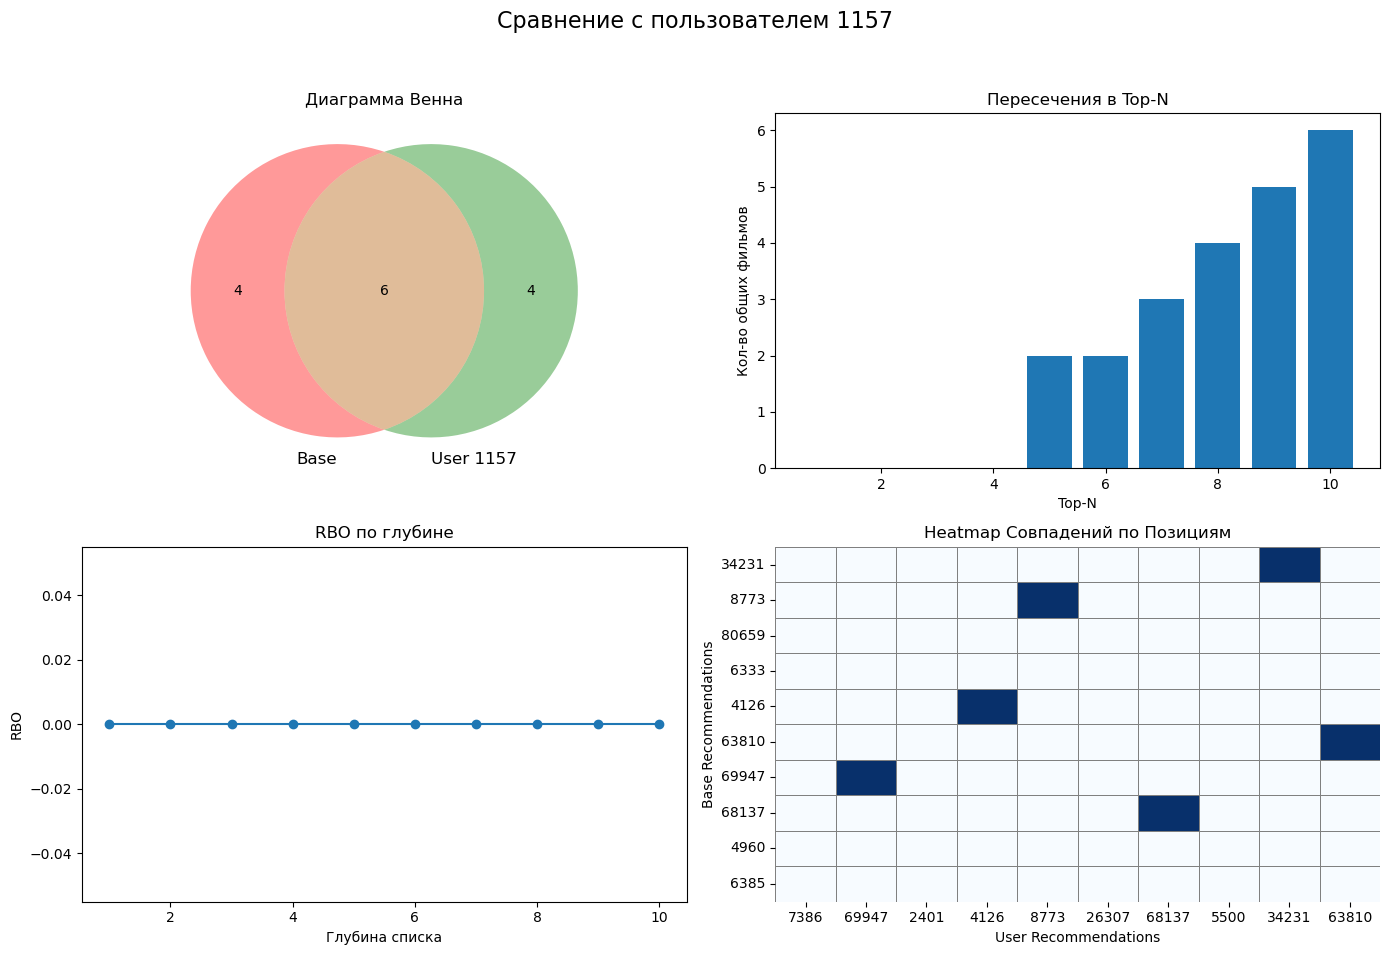


Сравнение с пользователем 1523
Jaccard Similarity: 0.1111111111111111
Precision@5: 0.0
Intersection Count: 2
RBO Score: 0.0


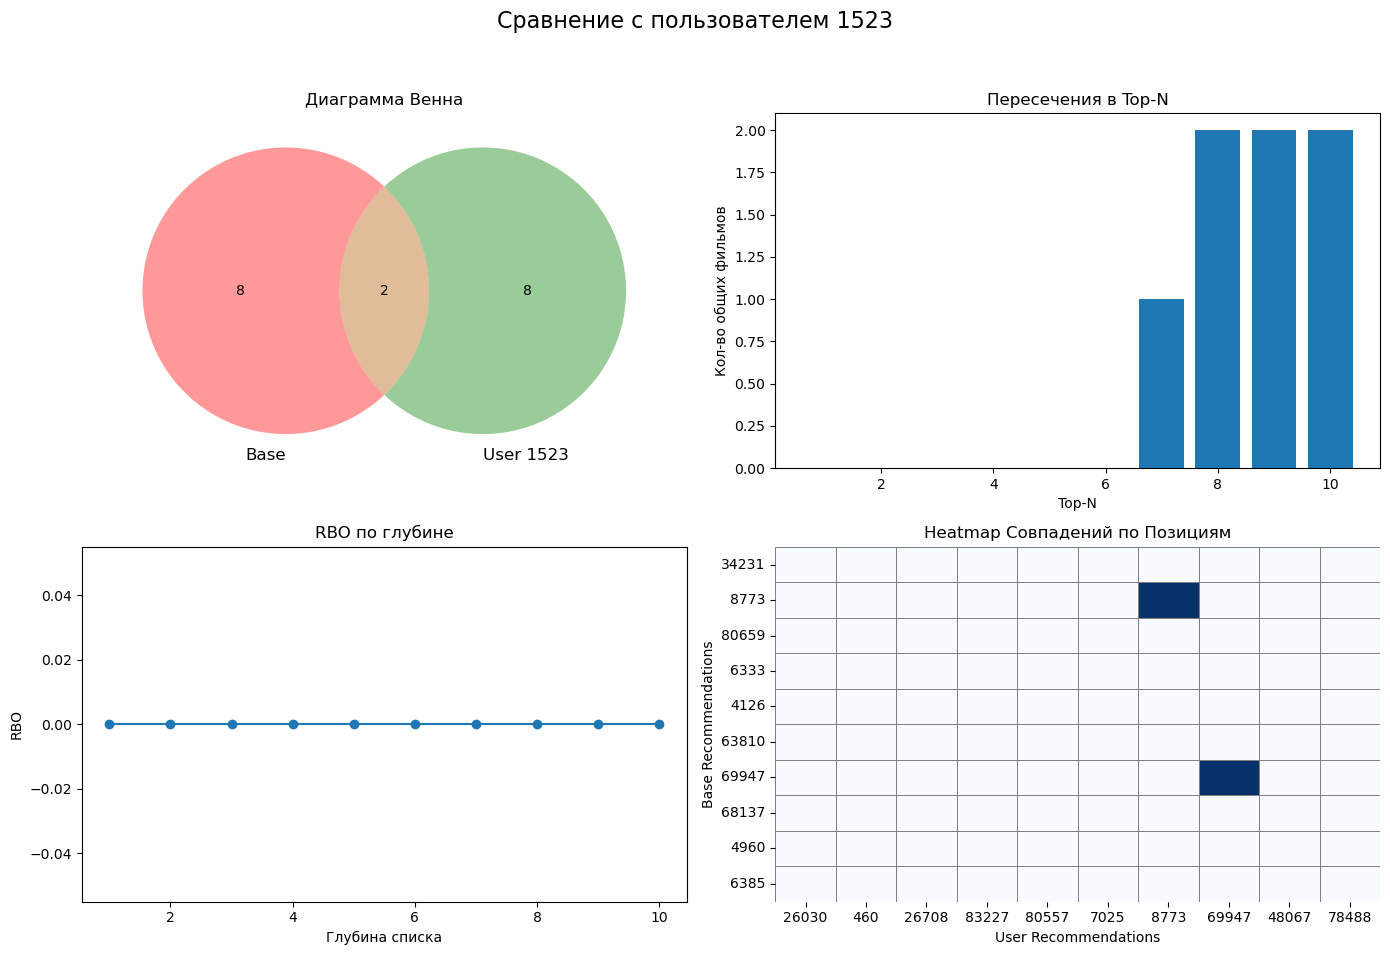


Сравнение с пользователем 762
Jaccard Similarity: 0.05263157894736842
Precision@5: 0.0
Intersection Count: 1
RBO Score: 0.0


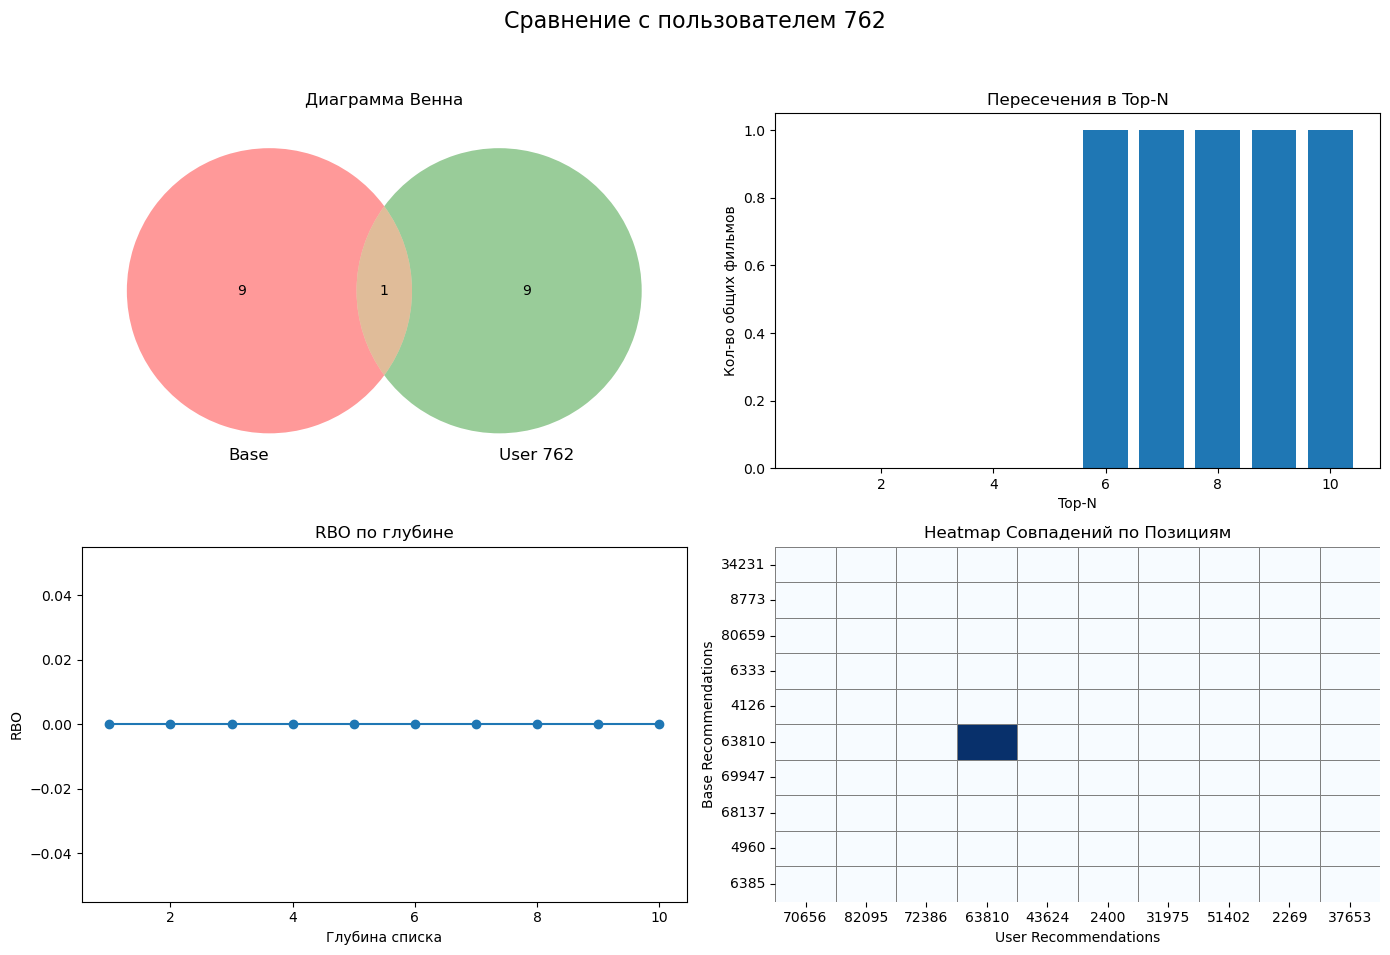


Сравнение с пользователем 733
Jaccard Similarity: 0.3333333333333333
Precision@5: 0.4
Intersection Count: 5
RBO Score: 0.9


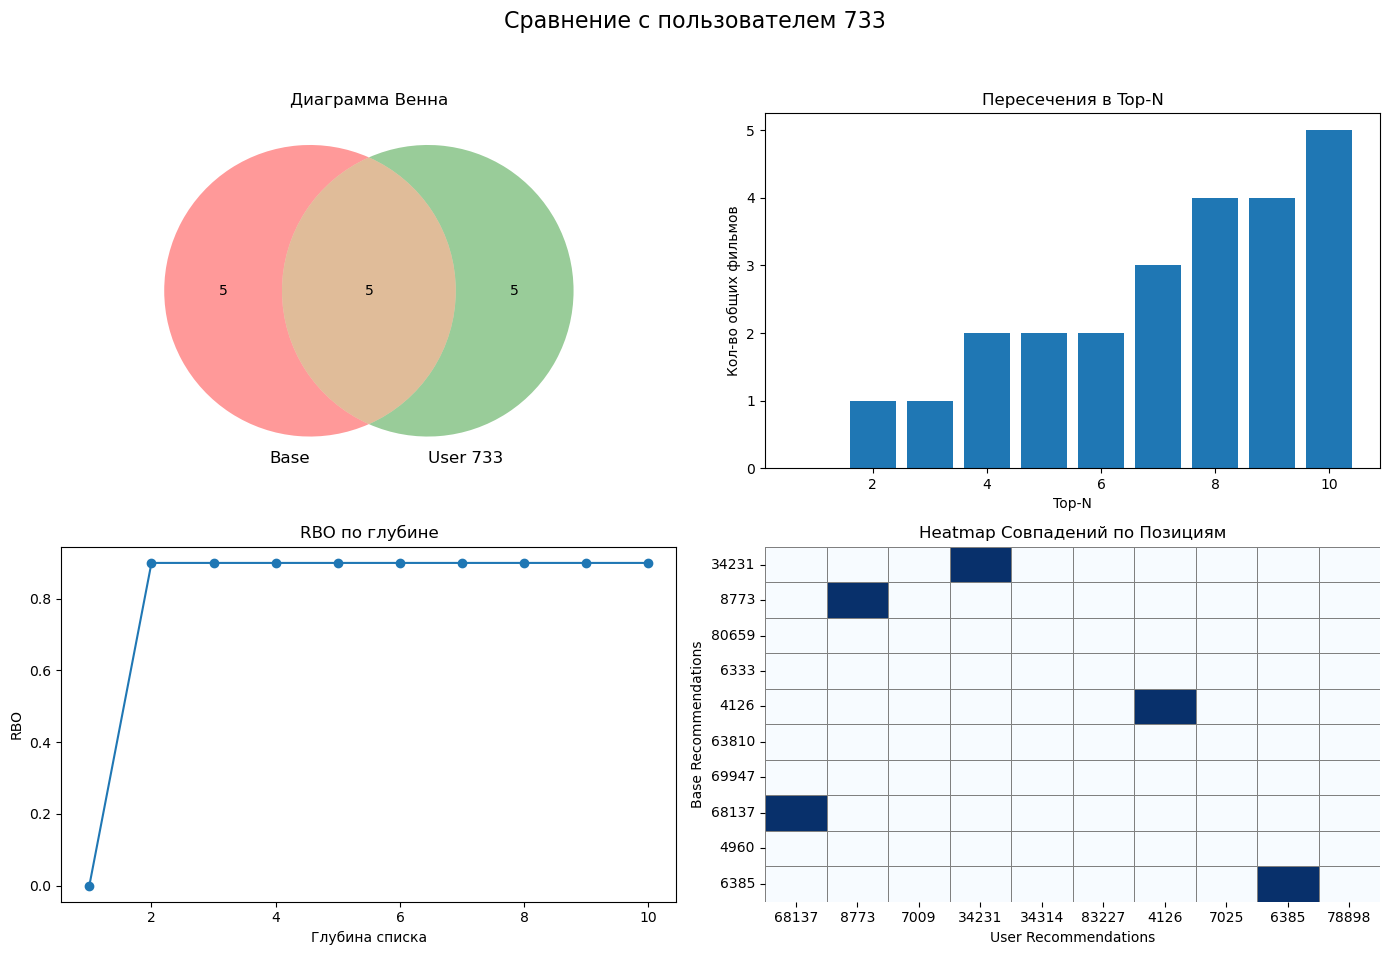

In [76]:
visualize_recommendations(final_after_df, similar_users_recommendations_after_df, top_n=10)

In [50]:
Daniil_rec

,movieId,title,genres,score
5,4265,Driven (2001),Action|Thriller,2.970856
12,62293,"Duchess, The (2008)",Drama|Romance,2.960736
7,5140,"Bad News Bears Go to Japan, The (1978)",Comedy,2.958763
1,912,Casablanca (1942),Drama|Romance,2.958626
11,8255,Chaos (Kaosu) (1999),Crime|Mystery|Thriller,2.955736
16,81027,Autumn Ball (SÃ¼gisball) (2007),Drama,2.955392
6,4568,Best of the Best (1989),Action,2.954297
13,76185,Miss MÃ©tÃ©o (2005),Comedy|Drama,2.953555
4,4130,Maid to Order (1987),Comedy|Fantasy,2.953538
2,1055,Shadow Conspiracy (1997),Thriller,2.953461


In [77]:
# Пример первого датафрейма
df = pd.DataFrame({
    'movieId': [4265, 62293, 5140, 912, 8255, 81027, 4568, 76185, 4130, 1055],
    'title': [
        'Driven (2001)', 'Duchess, The (2008)', 'Bad News Bears Go to Japan, The (1978)',
        'Casablanca (1942)', 'Chaos (Kaosu) (1999)', 'Autumn Ball (SÃ¼gisball) (2007)',
        'Best of the Best (1989)', 'Miss MÃ©tÃ©o (2005)', 'Maid to Order (1987)',
        'Shadow Conspiracy (1997)'
    ],
    'genres': [
        'Action|Thriller', 'Drama|Romance', 'Comedy', 'Drama|Romance',
        'Crime|Mystery|Thriller', 'Drama', 'Action', 'Comedy|Drama',
        'Comedy|Fantasy', 'Thriller'
    ],
    'score': [
        2.970856, 2.960736, 2.958763, 2.958626, 2.955736,
        2.955392, 2.954297, 2.953555, 2.953538, 2.953461
    ]
})

# Преобразование
df_transformed = df.copy()
df_transformed = df_transformed.rename(columns={
    'movieId': 'movie_id',
    'score': 'ensemble_score'
})

# Сбросить индекс для имитации левого ID столбца (как в примере)
df_transformed = df_transformed.reset_index()

# Вывод
df_transformed

,index,movie_id,title,genres,ensemble_score
0,0,4265,Driven (2001),Action|Thriller,2.970856
1,1,62293,"Duchess, The (2008)",Drama|Romance,2.960736
2,2,5140,"Bad News Bears Go to Japan, The (1978)",Comedy,2.958763
3,3,912,Casablanca (1942),Drama|Romance,2.958626
4,4,8255,Chaos (Kaosu) (1999),Crime|Mystery|Thriller,2.955736
5,5,81027,Autumn Ball (SÃ¼gisball) (2007),Drama,2.955392
6,6,4568,Best of the Best (1989),Action,2.954297
7,7,76185,Miss MÃ©tÃ©o (2005),Comedy|Drama,2.953555
8,8,4130,Maid to Order (1987),Comedy|Fantasy,2.953538
9,9,1055,Shadow Conspiracy (1997),Thriller,2.953461
